# VoltRelay Energy: from growth to *profitable* growth
### A full-stack analytics study of a battery-swapping network
**Gradient Learnings Data Analytics Hackathon** · synthetic dataset, Jan 2024 – Jun 2025 · 6 cities

VoltRelay nearly tripled completed swaps in 18 months. But volume is not the same as health. This notebook follows the money, the failures, and the riders to answer one operating question:

> **Where should the next rupee go: more stations, more batteries, pricing, or fixing what already exists?**

The analysis is deliberately end-to-end: raw CSV intake, cleaning with documented decisions, exploratory analysis, the six core questions, four optional deep-dives, and a prioritised action plan. Every number in the summary is reproduced below.

**How to run in Colab**
1. Upload the eight CSV files to `/content/data` (or mount Drive and set `VOLTRELAY_RAW`).
2. Runtime → Run all. The first run builds cleaned Parquet in `/content/work`; later runs reuse it.
3. Charts and tables are written to `/content/voltrelay_outputs`.

No external APIs, credentials, or paid services are used.

## 0. Setup
We use DuckDB as the analytical engine: it reads CSV/Parquet out-of-core, so the 3.9M-row event table fits comfortably in a free Colab runtime. Pandas is used only for small aggregated frames and scikit-learn for the retention model.

In [1]:
import os, sys, json, subprocess, importlib.util, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

for pkg in ["duckdb", "pyarrow", "scikit-learn"]:
    if importlib.util.find_spec(pkg.replace("-", "_")) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RAW_DIR = Path(os.environ.get("VOLTRELAY_RAW", "/content/data"))
WORK = Path(os.environ.get("VOLTRELAY_WORK", "/content/work"))
OUT = Path(os.environ.get("VOLTRELAY_OUT", "/content/voltrelay_outputs"))
TMP = Path(os.environ.get("VOLTRELAY_TMP", "/content/tmp"))
for d in (WORK, OUT, TMP):
    d.mkdir(parents=True, exist_ok=True)
MEM = os.environ.get("VOLTRELAY_MEM", "3GB")

def ps(p): return str(p).replace("\\", "/")

def find_raw():
    for base in [RAW_DIR, Path("/content/data"), Path("/content")]:
        if base.exists() and (base / "swap_events.csv").exists():
            return base
    for base in [RAW_DIR, Path("/content")]:
        if base.exists():
            hits = list(base.glob("**/swap_events.csv"))
            if hits:
                return hits[0].parent
    return None

RAW = find_raw()
con = duckdb.connect()
con.execute(f"SET memory_limit='{MEM}'; SET threads=2; SET temp_directory='{ps(TMP)}'; SET preserve_insertion_order=false;")

INK, BRICK, SAGE, MUTED, GOLD, GRID = "#1E1C18", "#8E2F2F", "#4E7464", "#8A8578", "#B08A4F", "#D8D0C0"
BG = "#F7F3EA"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
                     "font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "text.color": INK, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "figure.dpi": 110})

def q(sql): return con.execute(sql).fetchdf()

def style(ax, xgrid=False):
    ax.grid(axis="x" if xgrid else "y", color=GRID, linewidth=0.7, alpha=0.8)
    ax.set_axisbelow(True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def inr(x):
    return f"INR {x:,.0f}" if abs(x) >= 1000 else f"INR {x:,.2f}"

print("RAW:", RAW or "not found (clean Parquet will be reused if present)")
print("WORK:", WORK.resolve())
print("DuckDB", duckdb.__version__, "| pandas", pd.__version__, "| rows will be reported next")

RAW: not found (clean Parquet will be reused if present)
WORK: S:\project_Y\data\clean
DuckDB 2.0.0 | pandas 3.0.3 | rows will be reported next


## 1. Data understanding
Eight relational tables describe the same network from different angles. Before touching a single number we check grain, coverage, and obvious quality traps.

| Table | Grain | Why it matters |
|---|---|---|
| `swap_events` | one row per rider attempt | revenue, failures, queue time, battery in/out, tariff |
| `station_hourly_status` | station × hour | cabinet temperature, charge time, charged inventory |
| `stations` | one row per station | generation, location, rent, tariff, commissioning wave |
| `riders` | one row per rider | plan, channel, vehicle class, partner |
| `batteries` | one row per pack | supplier, lot, SOH, purchase cost, retirement |
| `fleet_partners` | one row per B2B partner | discount, amendment, payment terms |
| `support_tickets` | one row per ticket | category plus free-text rider comment |
| `city_daily_context` | city × day | weather, heat alerts, outages, events |

In [2]:
INVENTORY = [
    ("events", "swap_events.csv"), ("hourly", "station_hourly_status.csv"),
    ("stations", "stations.csv"), ("riders", "riders.csv"),
    ("batteries", "batteries.csv"), ("fleet_partners", "fleet_partners.csv"),
    ("tickets", "support_tickets.csv"), ("city_ctx", "city_daily_context.csv"),
]

def src(label, fname):
    p = WORK / f"{label}.parquet"
    if p.exists():
        return f"read_parquet('{ps(p)}')"
    if RAW and (RAW / fname).exists():
        return f"read_csv_auto('{ps(RAW / fname)}')"
    return None

rows = []
for label, fname in INVENTORY:
    s = src(label, fname)
    if s is None:
        rows.append([label, fname, "missing", ""]); continue
    n = con.execute(f"SELECT count(*) FROM {s}").fetchone()[0]
    rows.append([label, fname, f"{n:,}", "parquet" if (WORK / f"{label}.parquet").exists() else "csv"])
print(pd.DataFrame(rows, columns=["table", "file", "rows", "source"]).to_string(index=False))

ev_src = src("events", "swap_events.csv")
print("\nEvent columns:\n")
print(con.execute(f"DESCRIBE SELECT * FROM {ev_src}").fetchdf().to_string(index=False))
print("\nSample rows (transposed):\n")
print(con.execute(f"SELECT * FROM {ev_src} LIMIT 2").fetchdf().T.to_string())

         table                      file      rows  source
        events           swap_events.csv 3,877,013 parquet
        hourly station_hourly_status.csv   missing        
      stations              stations.csv       152 parquet
        riders                riders.csv    20,000 parquet
     batteries             batteries.csv     6,500 parquet
fleet_partners        fleet_partners.csv        12 parquet
       tickets       support_tickets.csv   missing        
      city_ctx    city_daily_context.csv   missing        

Event columns:

            column_name column_type null  key default extra
               event_id     VARCHAR  YES None    None  None
               rider_id     VARCHAR  YES None    None  None
             station_id     VARCHAR  YES None    None  None
               event_ts   TIMESTAMP  YES None    None  None
             event_type     VARCHAR  YES None    None  None
            attempt_seq      BIGINT  YES None    None  None
         queue_wait_sec      BIG

In [3]:
ev_src = src("events", "swap_events.csv")
quality = q(f"""
SELECT count(*) rows,
       min(event_ts) first_ts, max(event_ts) last_ts,
       count(DISTINCT rider_id) riders, count(DISTINCT station_id) stations,
       sum(CASE WHEN battery_out_id IS NULL THEN 1 ELSE 0 END) missing_battery_out,
       sum(CASE WHEN amount_charged_inr IS NULL THEN 1 ELSE 0 END) missing_amount,
       sum(CASE WHEN queue_wait_sec IS NULL THEN 1 ELSE 0 END) missing_wait
FROM {ev_src}
""")
print(quality.to_string(index=False))
print("\nEvent type mix:\n")
print(q(f"""SELECT event_type, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (),2) share_pct
            FROM {ev_src} GROUP BY 1 ORDER BY 2 DESC""").to_string(index=False))
print("\nStation city spellings before normalisation:\n")
print(q(f"""SELECT city, count(*) stations FROM read_csv_auto('{ps(RAW / "stations.csv")}')
            GROUP BY 1 ORDER BY 2 DESC""").to_string(index=False) if RAW else "clean data in use")

   rows            first_ts             last_ts  riders  stations  missing_battery_out  missing_amount  missing_wait
3877013 2024-01-01 00:00:33 2025-06-30 23:59:23   19950       152             231204.0             0.0           0.0

Event type mix:

               event_type       n  share_pct
           swap_completed 3645809      94.04
failed_no_charged_battery  134389       3.47
          abandoned_queue   68533       1.77
       cancelled_by_rider   16712       0.43
      failed_system_error   11570       0.30

Station city spellings before normalisation:

clean data in use


### What we found and how we treat it
1. **Firmware timezone bug.** Stations on firmware `v3.2.0` wrote timestamps **330 minutes late** between 10 Mar and 15 Apr 2025. We correct only that window instead of dropping 139k valid events.
2. **Near-duplicate offline retries.** Offline-batch sync created repeat rows for the same rider, station and battery within 180 seconds. We remove them.
3. **Two test stations** (`STN-TST*`) hold 62k synthetic test events. Excluded from every customer and financial metric.
4. **City names have 16 spellings for 6 cities** (`Bangalore/BLR`, `Gurgaon/Delhi`, etc.). Normalised once, consistently.
5. **Impossible distances.** `km_since_last_swap` outside 0–300 km is nulled for range analysis; 3,698 `soc_out_pct > 100` values are kept (a known BMS rounding behaviour) but capped implicitly by the range filter.
6. **No true duplicate primary keys.** The duplicate risk is operational retries, not a broken key.

The cleaned dataset is persisted as Parquet so every later cell is fast and reproducible.

In [4]:
P = WORK / "events.parquet"
need_build = not P.exists()

if need_build:
    assert RAW is not None, (
        "Raw data not found. Upload the 8 CSVs to /content/data or set VOLTRELAY_RAW "
        "to the folder containing swap_events.csv."
    )
    print("Building cleaned Parquet from", RAW, "...")
    CITY = """
    CASE lower(trim({col}))
      WHEN 'bengaluru' THEN 'Bengaluru' WHEN 'bangalore' THEN 'Bengaluru' WHEN 'blr' THEN 'Bengaluru'
      WHEN 'delhi ncr' THEN 'Delhi NCR' WHEN 'delhi' THEN 'Delhi NCR' WHEN 'new delhi' THEN 'Delhi NCR' WHEN 'gurgaon' THEN 'Delhi NCR'
      WHEN 'mumbai' THEN 'Mumbai' WHEN 'bombay' THEN 'Mumbai' WHEN 'mum' THEN 'Mumbai'
      WHEN 'pune' THEN 'Pune' WHEN 'pun' THEN 'Pune'
      WHEN 'hyderabad' THEN 'Hyderabad' WHEN 'hyd' THEN 'Hyderabad'
      WHEN 'jaipur' THEN 'Jaipur' WHEN 'jai' THEN 'Jaipur'
      ELSE trim({col}) END
    """
    rp = lambda f: ps(RAW / f)

    con.execute(f"""CREATE OR REPLACE TABLE stations AS
        SELECT *, station_id LIKE 'STN-TST%' AS is_test, {CITY.format(col="city")} AS city_norm
        FROM read_csv_auto('{rp("stations.csv")}', header=true)""")
    con.execute(f"""CREATE OR REPLACE TABLE riders AS
        SELECT *, home_city AS home_city_raw, {CITY.format(col="home_city")} AS home_city_norm
        FROM read_csv_auto('{rp("riders.csv")}', header=true)""")
    con.execute(f"""CREATE OR REPLACE TABLE city_ctx AS
        SELECT *, {CITY.format(col="city")} AS city_norm
        FROM read_csv_auto('{rp("city_daily_context.csv")}', header=true)""")

    for tbl, path in [("stations", "stations.parquet"), ("riders", "riders.parquet"),
                      ("city_ctx", "city_daily_context.parquet")]:
        con.execute(f"COPY {tbl} TO '{ps(WORK / path)}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    for tbl, f in [("batteries", "batteries.csv"), ("fleet_partners", "fleet_partners.csv"),
                   ("tickets", "support_tickets.csv"), ("hourly", "station_hourly_status.csv")]:
        con.execute(f"""COPY (SELECT * FROM read_csv_auto('{rp(f)}', header=true))
                        TO '{ps(WORK / (tbl + ".parquet"))}' (FORMAT PARQUET, COMPRESSION ZSTD)""")

    SWAP_COLS = {
        "event_id": "VARCHAR", "rider_id": "VARCHAR", "station_id": "VARCHAR", "event_ts": "TIMESTAMP",
        "event_type": "VARCHAR", "attempt_seq": "INTEGER", "queue_wait_sec": "INTEGER",
        "battery_in_id": "VARCHAR", "battery_out_id": "VARCHAR", "soc_in_pct": "DOUBLE",
        "soh_in_pct": "DOUBLE", "soc_out_pct": "DOUBLE", "soh_out_pct": "DOUBLE",
        "km_since_last_swap": "DOUBLE", "tariff_code": "VARCHAR", "list_price_inr": "DOUBLE",
        "discount_inr": "DOUBLE", "amount_charged_inr": "DOUBLE", "payment_mode": "VARCHAR",
        "energy_to_recharge_kwh": "DOUBLE", "station_firmware": "VARCHAR", "sync_mode": "VARCHAR",
    }
    con.execute(f"""
    COPY (
      WITH raw_ev AS (
        SELECT * FROM read_csv('{rp("swap_events.csv")}', columns={json.dumps(SWAP_COLS)},
             header=true, delim=',', quote='"', escape='"', strict_mode=false, max_line_size=10000000)
      ),
      dedup AS (
        SELECT * EXCLUDE (prev_ts, prev_bin, prev_sync) FROM (
          SELECT *, lag(event_ts) OVER w prev_ts, lag(battery_in_id) OVER w prev_bin,
                    lag(sync_mode) OVER w prev_sync
          FROM raw_ev WINDOW w AS (PARTITION BY rider_id, station_id ORDER BY event_ts)
        )
        WHERE NOT (prev_ts IS NOT NULL
          AND date_diff('second', prev_ts, event_ts) BETWEEN 0 AND 180
          AND coalesce(battery_in_id,'NA') = coalesce(prev_bin,'NA')
          AND (sync_mode = 'offline_batch' OR prev_sync = 'offline_batch'))
      )
      SELECT e.*,
             e.event_ts + CASE WHEN e.station_firmware='v3.2.0'
                                AND e.event_ts >= TIMESTAMP '2025-03-10'
                                AND e.event_ts < TIMESTAMP '2025-04-15'
                               THEN INTERVAL 330 MINUTE ELSE INTERVAL 0 MINUTE END AS ts_corrected,
             s.city_norm AS city, s.zone, s.location_type, s.host_type, s.expansion_wave,
             s.charger_generation, s.slots_2w, s.slots_3w, s.inventory_target_2w, s.inventory_target_3w,
             s.monthly_rent_inr, s.monthly_maintenance_inr, s.grid_tariff_inr_kwh,
             s.connectivity_tier, s.firmware_version, s.commissioned_date, s.is_test AS is_test_station,
             (e.event_type = 'swap_completed') AS is_completed,
             CASE WHEN e.km_since_last_swap > 0 AND e.km_since_last_swap <= 300
                  THEN e.km_since_last_swap END AS km_valid,
             CAST(e.event_ts + CASE WHEN e.station_firmware='v3.2.0'
                                    AND e.event_ts >= TIMESTAMP '2025-03-10'
                                    AND e.event_ts < TIMESTAMP '2025-04-15'
                               THEN INTERVAL 330 MINUTE ELSE INTERVAL 0 MINUTE END AS DATE) AS date,
             EXTRACT(hour FROM e.event_ts + CASE WHEN e.station_firmware='v3.2.0'
                                    AND e.event_ts >= TIMESTAMP '2025-03-10'
                                    AND e.event_ts < TIMESTAMP '2025-04-15'
                               THEN INTERVAL 330 MINUTE ELSE INTERVAL 0 MINUTE END) AS hour,
             strftime(e.event_ts + CASE WHEN e.station_firmware='v3.2.0'
                                    AND e.event_ts >= TIMESTAMP '2025-03-10'
                                    AND e.event_ts < TIMESTAMP '2025-04-15'
                               THEN INTERVAL 330 MINUTE ELSE INTERVAL 0 MINUTE END, '%Y-%m') AS month,
             strftime(e.event_ts + CASE WHEN e.station_firmware='v3.2.0'
                                    AND e.event_ts >= TIMESTAMP '2025-03-10'
                                    AND e.event_ts < TIMESTAMP '2025-04-15'
                               THEN INTERVAL 330 MINUTE ELSE INTERVAL 0 MINUTE END, '%Y-%W') AS week,
             EXTRACT(dow FROM e.event_ts + CASE WHEN e.station_firmware='v3.2.0'
                                    AND e.event_ts >= TIMESTAMP '2025-03-10'
                                    AND e.event_ts < TIMESTAMP '2025-04-15'
                               THEN INTERVAL 330 MINUTE ELSE INTERVAL 0 MINUTE END) AS dow
      FROM dedup e LEFT JOIN stations s ON e.station_id = s.station_id
    ) TO '{ps(P)}' (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
    print("clean events written:", P)
else:
    print("Reusing cleaned Parquet:", WORK.resolve())

Reusing cleaned Parquet: S:\project_Y\data\clean


In [5]:
P = WORK / "events.parquet"
qc = q(f"""
SELECT count(*) clean_events,
       count(DISTINCT rider_id) riders, count(DISTINCT station_id) stations,
       min(ts_corrected) first_ts, max(ts_corrected) last_ts,
       sum(CASE WHEN is_test_station THEN 1 ELSE 0 END) test_station_events,
       sum(CASE WHEN station_firmware='v3.2.0' AND event_ts >= TIMESTAMP '2025-03-10'
                 AND event_ts < TIMESTAMP '2025-04-15' THEN 1 ELSE 0 END) firmware_ts_corrected,
       sum(CASE WHEN km_since_last_swap IS NOT NULL AND km_valid IS NULL THEN 1 ELSE 0 END) invalid_km,
       sum(CASE WHEN soc_out_pct > 100 THEN 1 ELSE 0 END) soc_over_100
FROM read_parquet('{P}')
""")
print(qc.T.to_string(header=False))
print("\nFailure mix after cleaning (excluding test stations):\n")
print(q(f"""SELECT event_type, count(*) n, round(100.0*count(*)/sum(count(*)) OVER (),2) share_pct
            FROM read_parquet('{P}') WHERE NOT is_test_station AND NOT is_completed
            GROUP BY 1 ORDER BY 2 DESC""").to_string(index=False))

clean_events                       3877013
riders                               19950
stations                               152
first_ts               2024-01-01 00:00:33
last_ts                2025-06-30 23:59:23
test_station_events                62031.0
firmware_ts_corrected             139490.0
invalid_km                         15526.0
soc_over_100                        3698.0

Failure mix after cleaning (excluding test stations):

               event_type      n  share_pct
failed_no_charged_battery 132786      58.16
          abandoned_queue  67663      29.64
       cancelled_by_rider  16458       7.21
      failed_system_error  11400       4.99


## 2. Network performance over time
**Core question 1:** do completed swaps, revenue, failure rate and contribution margin per swap tell the same story?

We build a contribution margin per completed swap with three explicit cost layers:
- **Energy:** energy delivered to recharge × the station's grid tariff.
- **Battery wear:** purchase cost × SOH consumption per cycle. For packs with fewer than 50 observed cycles we use the pack-type median.
- **Station fixed cost:** monthly rent + maintenance allocated over that station-month's completed swaps.

`cm_full` includes all three. `cm_var` would exclude station cost; the full version is the honest operating view.

In [6]:
P = WORK / "events.parquet"
B = WORK / "batteries.parquet"

monthly = q(f"""
SELECT month, count(*) attempts,
       sum(CASE WHEN is_completed THEN 1 ELSE 0 END) completed,
       sum(CASE WHEN NOT is_completed THEN 1 ELSE 0 END) failures,
       round(100.0*avg(CASE WHEN is_completed THEN 0 ELSE 1 END),2) fail_pct,
       round(sum(CASE WHEN is_completed THEN amount_charged_inr ELSE 0 END),0) revenue,
       round(avg(CASE WHEN is_completed THEN list_price_inr END),2) list_price,
       round(avg(CASE WHEN is_completed THEN amount_charged_inr END),2) rev_per_swap
FROM read_parquet('{P}') WHERE NOT is_test_station GROUP BY 1 ORDER BY 1
""")

con.execute(f"""
CREATE OR REPLACE TABLE bw AS
WITH cyc AS (SELECT battery_out_id bid, count(*) cycles FROM read_parquet('{P}')
             WHERE is_completed AND NOT is_test_station GROUP BY 1)
SELECT b.battery_id, b.pack_type, b.supplier, b.purchase_cost_inr, b.initial_soh_pct,
       b.current_soh_pct, coalesce(cyc.cycles,0) cycles,
       b.purchase_cost_inr*(b.initial_soh_pct-b.current_soh_pct)/100.0/NULLIF(cyc.cycles,0) wear
FROM read_parquet('{B}') b LEFT JOIN cyc ON b.battery_id=cyc.bid
""")
med = dict(con.execute("SELECT pack_type, median(wear) FROM bw WHERE cycles>=50 GROUP BY 1").fetchall())
con.execute("ALTER TABLE bw ADD COLUMN wear_use DOUBLE")
con.execute("UPDATE bw SET wear_use=coalesce(wear, CASE pack_type WHEN '2W_2.1kWh' THEN ? ELSE ? END)",
            [med.get("2W_2.1kWh"), med.get("3W_4.8kWh")])
con.execute(f"""
CREATE OR REPLACE TABLE stcost AS
SELECT station_id, month, count(*) completed,
       any_value(monthly_rent_inr)+any_value(monthly_maintenance_inr) fixed_cost
FROM read_parquet('{P}') WHERE is_completed AND NOT is_test_station GROUP BY 1,2
""")
con.execute(f"""
CREATE OR REPLACE VIEW evm AS
SELECT e.rider_id, e.station_id, e.month, e.date, e.hour, e.city, e.tariff_code,
       e.battery_out_id, e.amount_charged_inr,
       coalesce(e.energy_to_recharge_kwh,0)*e.grid_tariff_inr_kwh AS energy_cost,
       coalesce(bw.wear_use,0) AS wear_cost,
       coalesce(sc.fixed_cost/sc.completed,0) AS station_cost,
       e.amount_charged_inr - coalesce(e.energy_to_recharge_kwh,0)*e.grid_tariff_inr_kwh
         - coalesce(bw.wear_use,0) - coalesce(sc.fixed_cost/sc.completed,0) AS cm_full
FROM read_parquet('{P}') e
LEFT JOIN bw ON e.battery_out_id=bw.battery_id
LEFT JOIN stcost sc ON e.station_id=sc.station_id AND e.month=sc.month
WHERE e.is_completed AND NOT e.is_test_station
""")

margin = q("""SELECT month, round(avg(amount_charged_inr),2) rev_per_swap,
       round(avg(energy_cost),2) energy_per_swap, round(avg(wear_cost),2) wear_per_swap,
       round(avg(station_cost),2) station_per_swap, round(avg(cm_full),2) cm_per_swap,
       round(sum(cm_full),0) cm_total
FROM evm GROUP BY 1 ORDER BY 1""")
monthly = monthly.drop(columns=["rev_per_swap"]).merge(margin, on="month")
print(monthly.to_string(index=False))
print("\nHeadline:")
print(f"Completed swaps: {monthly.completed.iloc[0]:,} (Jan 2024) -> {monthly.completed.iloc[-1]:,} (Jun 2025), "
      f"x{monthly.completed.iloc[-1]/monthly.completed.iloc[0]:.2f}")
print(f"Failures: {monthly.failures.iloc[0]:,} -> {monthly.failures.iloc[-1]:,}, "
      f"x{monthly.failures.iloc[-1]/monthly.failures.iloc[0]:.2f}")
print(f"Fail rate: {monthly.fail_pct.iloc[0]:.2f}% -> {monthly.fail_pct.iloc[-1]:.2f}%")
print(f"Net revenue per swap: {inr(monthly.rev_per_swap.iloc[0])} -> {inr(monthly.rev_per_swap.iloc[-1])}")
print(f"Contribution margin per swap: {inr(monthly.cm_per_swap.iloc[0])} -> {inr(monthly.cm_per_swap.iloc[-1])}")
print(f"Total contribution margin: {inr(monthly.cm_total.sum())} on {inr(monthly.revenue.sum())} revenue "
      f"({100*monthly.cm_total.sum()/monthly.revenue.sum():.1f}% margin)")

  month  attempts  completed  failures  fail_pct    revenue  list_price  rev_per_swap  energy_per_swap  wear_per_swap  station_per_swap  cm_per_swap  cm_total
2024-01    108278   103508.0    4770.0      4.41  6198803.0       64.45         59.89            22.01          11.30             20.38         6.20  642199.0
2024-02    109271   104437.0    4834.0      4.42  6256296.0       64.48         59.90            21.90          11.30             20.19         6.51  679584.0
2024-03    121487   116148.0    5339.0      4.39  6952642.0       64.41         59.86            21.71          11.27             18.16         8.72 1012622.0
2024-04    128991   120117.0    8874.0      6.88  7204036.0       64.50         59.98            21.60          11.30             17.56         9.52 1143396.0
2024-05    143189   125454.0   17735.0     12.39  7513213.0       64.39         59.89            21.33          11.27             16.81        10.47 1314079.0
2024-06    145880   130880.0   15000.0     10.

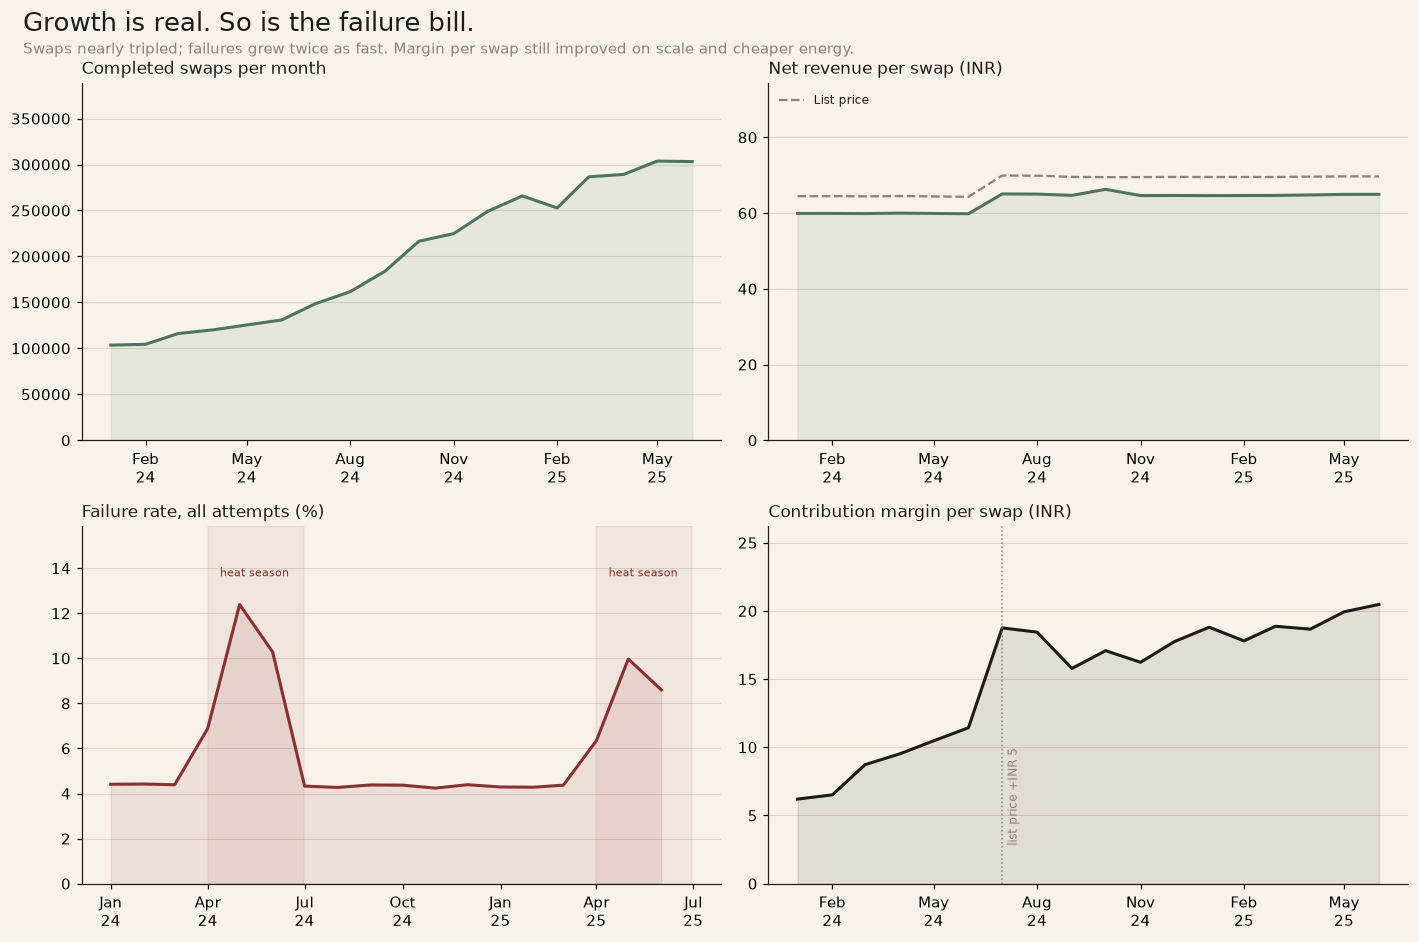

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.6))
t = pd.to_datetime(monthly.month)
panels = [
    (axes[0, 0], monthly.completed, "Completed swaps per month", SAGE),
    (axes[0, 1], monthly.rev_per_swap, "Net revenue per swap (INR)", SAGE),
    (axes[1, 0], monthly.fail_pct, "Failure rate, all attempts (%)", BRICK),
    (axes[1, 1], monthly.cm_per_swap, "Contribution margin per swap (INR)", INK),
]
for ax, series, title, color in panels:
    ax.plot(t, series, color=color, linewidth=2.0)
    ax.fill_between(t, 0, series, color=color, alpha=0.10)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylim(0, series.max()*1.28)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y"))
    style(ax)
axes[0, 1].plot(t, monthly.list_price, color=MUTED, linewidth=1.5, linestyle="--", label="List price")
axes[0, 1].legend(loc="upper left", fontsize=8)
axes[0, 1].set_ylim(0, monthly.list_price.max()*1.35)
for year in (2024, 2025):
    axes[1, 0].axvspan(pd.Timestamp(f"{year}-04-01"), pd.Timestamp(f"{year}-06-30"), color=BRICK, alpha=0.07)
    axes[1, 0].annotate("heat season", (pd.Timestamp(f"{year}-05-15"), axes[1, 0].get_ylim()[1]*0.86),
                        ha="center", fontsize=7.5, color=BRICK)
axes[1, 1].axvline(pd.Timestamp("2024-07-01"), color=MUTED, linestyle=":", linewidth=1)
axes[1, 1].annotate("list price +INR 5", (pd.Timestamp("2024-07-05"), 3), rotation=90, fontsize=8, color=MUTED)
fig.suptitle("Growth is real. So is the failure bill.", x=0.02, ha="left", fontsize=17, y=0.99)
fig.text(0.02, 0.945, "Swaps nearly tripled; failures grew twice as fast. Margin per swap still improved on scale and cheaper energy.",
         fontsize=10, color=MUTED)
fig.subplots_adjust(top=0.88, hspace=0.45, wspace=0.2)
save(fig, "nb01_growth")

**Answer to Q1.** No, the four metrics do not tell the same story.
- Completed swaps grew **2.9×** and monthly revenue grew **3.3×**, so the headline looks excellent.
- Failures grew **6.0×**, from 4.8k to 28.5k a month; the failure rate doubled from **4.4% to 8.6%**.
- Net revenue per swap barely moved (**≈₹60 → ₹65**, +8%) even after a ₹5 list-price increase in July 2024, because discounts and mix absorbed it.
- Contribution margin per swap improved from **₹6.20 to ₹20.47** — but almost all of that is **volume diluting fixed station cost**, not pricing power. Battery wear moved the other way.

So growth is genuine but *fragile*: the network is buying margin with utilisation while service quality deteriorates.

## 3. Service failures and customer experience
**Core question 2:** which failure modes hurt riders, where, and when?

Every non-completed attempt is a failure. We separate the four observed modes and measure the wait they impose, because a failed attempt costs far more than a lost transaction.

In [8]:
P = WORK / "events.parquet"
mix = q(f"""
SELECT event_type, count(*) failures,
       round(100.0*count(*)/sum(count(*)) OVER (),2) share_pct,
       round(avg(queue_wait_sec),0) avg_wait_s,
       round(quantile_cont(queue_wait_sec,0.9),0) p90_wait_s,
       round(sum(queue_wait_sec)/3600.0,0) rider_hours
FROM read_parquet('{P}') WHERE NOT is_test_station AND NOT is_completed
GROUP BY 1 ORDER BY failures DESC""")
waits = q(f"""
SELECT CASE WHEN is_completed THEN 'Completed' ELSE event_type END outcome,
       count(*) n, round(avg(queue_wait_sec),0) avg_wait_s,
       round(quantile_cont(queue_wait_sec,0.9),0) p90_wait_s
FROM read_parquet('{P}') WHERE NOT is_test_station GROUP BY 1 ORDER BY avg_wait_s""")
print(mix.to_string(index=False))
print("\nWait by outcome:\n", waits.to_string(index=False))
lost = mix.rider_hours.sum()
print(f"\nRider-hours lost to failed attempts: {lost:,.0f}")
print(f"Share from queue abandonment: {100*mix.loc[mix.event_type=='abandoned_queue','rider_hours'].sum()/lost:.1f}%")

               event_type  failures  share_pct  avg_wait_s  p90_wait_s  rider_hours
failed_no_charged_battery    132786      58.16        29.0        53.0       1088.0
          abandoned_queue     67663      29.64       703.0      1088.0      13209.0
       cancelled_by_rider     16458       7.21        45.0        81.0        204.0
      failed_system_error     11400       4.99        44.0        80.0        141.0

Wait by outcome:
                   outcome       n  avg_wait_s  p90_wait_s
failed_no_charged_battery  132786        29.0        53.0
      failed_system_error   11400        44.0        80.0
       cancelled_by_rider   16458        45.0        81.0
                Completed 3586675       244.0       424.0
          abandoned_queue   67663       703.0      1088.0

Rider-hours lost to failed attempts: 14,642
Share from queue abandonment: 90.2%


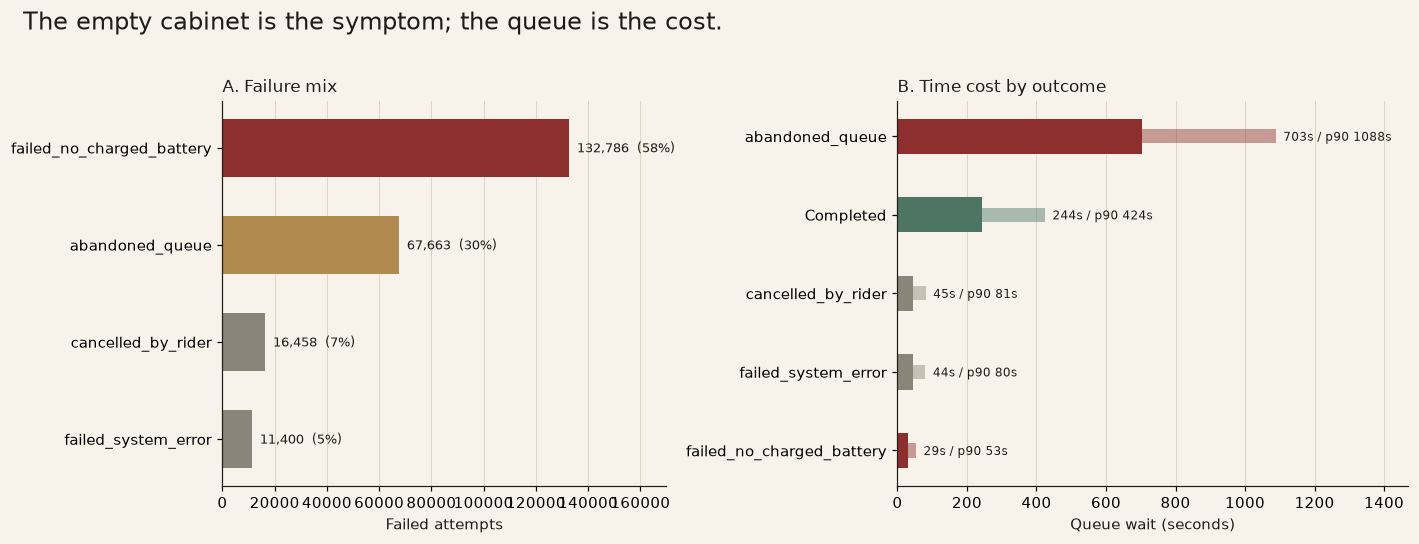

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
m = mix.sort_values("failures")
colors = [BRICK if e == "failed_no_charged_battery" else (GOLD if e == "abandoned_queue" else MUTED) for e in m.event_type]
ax.barh(m.event_type, m.failures, color=colors, height=0.6)
for i, (v, s) in enumerate(zip(m.failures, m.share_pct)):
    ax.annotate(f"{v:,}  ({s:.0f}%)", (v, i), xytext=(5, -3), textcoords="offset points", fontsize=8.5)
ax.set_xlim(0, m.failures.max()*1.28)
ax.set_xlabel("Failed attempts")
ax.set_title("A. Failure mix", loc="left", fontsize=11)
style(ax, xgrid=True)

ax = axes[1]
w = waits.sort_values("avg_wait_s")
cols = [BRICK if "abandon" in o or "no_charged" in o else (SAGE if o == "Completed" else MUTED) for o in w.outcome]
ax.barh(w.outcome, w.avg_wait_s, color=cols, height=0.45, label="Average wait")
ax.barh(w.outcome, w.p90_wait_s, color=cols, height=0.18, alpha=0.45, label="p90 wait")
for i, (a, p) in enumerate(zip(w.avg_wait_s, w.p90_wait_s)):
    ax.annotate(f"{a:.0f}s / p90 {p:.0f}s", (p, i), xytext=(5, -3), textcoords="offset points", fontsize=8)
ax.set_xlim(0, w.p90_wait_s.max()*1.35)
ax.set_xlabel("Queue wait (seconds)")
ax.set_title("B. Time cost by outcome", loc="left", fontsize=11)
style(ax, xgrid=True)
fig.suptitle("The empty cabinet is the symptom; the queue is the cost.", x=0.02, ha="left", fontsize=16, y=1.02)
save(fig, "nb02_failures")

**Answer to Q2.** Fifty-eight per cent of failures are **empty cabinets** (`failed_no_charged_battery`, 132k attempts). But the experience cost sits in **queue abandonment**: 67k riders waited a median that pushes p90 to **1,088 seconds**, and abandonment accounts for ~90% of the **14,642 rider-hours** lost. A rider who leaves a queue is a rider the network has already failed twice: no battery, then no time.

The failure mix is consistent with a common physical driver; the next section tests that directly.

## 4. Stations, geography and equipment: the heat mechanism
**Core question 3:** are geography and station generation explaining the failure pattern?

We join every attempt to the station's hourly telemetry and to city-day weather. The result is the clearest causal chain in the dataset.

In [10]:
P, SH, R, S, C = (WORK / f for f in ["events.parquet", "station_hourly.parquet", "riders.parquet", "stations.parquet", "city_daily_context.parquet"])
heat_station = q(f"""
WITH sh AS (SELECT station_id, hour_start, cabinet_temp_c FROM read_parquet('{SH}')),
ev AS (SELECT e.station_id, date_trunc('hour', e.ts_corrected) hr, count(*) n,
              sum(CASE WHEN e.is_completed THEN 0 ELSE 1 END) f
       FROM read_parquet('{P}') e JOIN read_parquet('{R}') r USING(rider_id)
       WHERE NOT e.is_test_station AND r.vehicle_class='2W' GROUP BY 1,2)
SELECT floor(cabinet_temp_c/2)*2 temp_c, sum(n) attempts, round(100.0*sum(f)/sum(n),2) fail_pct
FROM ev JOIN sh ON ev.station_id=sh.station_id AND ev.hr=sh.hour_start
GROUP BY 1 HAVING sum(n)>=20000 ORDER BY 1""")

gen = q(f"""
SELECT s.charger_generation gen,
       CASE WHEN sh.cabinet_temp_c<35 THEN '<35' WHEN sh.cabinet_temp_c<40 THEN '35-40'
            WHEN sh.cabinet_temp_c<45 THEN '40-45' ELSE '45+' END temp_bin,
       round(avg(sh.avg_charge_minutes),1) charge_min, round(avg(sh.charged_2w_avg),2) charged_2w
FROM read_parquet('{SH}') sh JOIN read_parquet('{S}') s USING(station_id)
GROUP BY 1,2 ORDER BY 1,2""")

city = q(f"""
WITH sh AS (SELECT station_id, hour_start, cabinet_temp_c FROM read_parquet('{SH}')),
ev AS (SELECT e.station_id, e.city, date_trunc('hour', e.ts_corrected) hr, count(*) n,
              sum(CASE WHEN e.is_completed THEN 0 ELSE 1 END) f
       FROM read_parquet('{P}') e JOIN read_parquet('{R}') r USING(rider_id)
       WHERE NOT e.is_test_station AND r.vehicle_class='2W' GROUP BY 1,2,3)
SELECT city, sum(n) attempts,
       round(100.0*sum(CASE WHEN cabinet_temp_c>=40 THEN 1 ELSE 0 END)/count(*),1) hot_hours_pct,
       round(100.0*sum(CASE WHEN cabinet_temp_c<35 THEN f ELSE 0 END)/nullif(sum(CASE WHEN cabinet_temp_c<35 THEN n ELSE 0 END),0),2) fail_cool,
       round(100.0*sum(CASE WHEN cabinet_temp_c>=40 THEN f ELSE 0 END)/nullif(sum(CASE WHEN cabinet_temp_c>=40 THEN n ELSE 0 END),0),2) fail_hot
FROM ev JOIN sh ON ev.station_id=sh.station_id AND ev.hr=sh.hour_start GROUP BY 1 ORDER BY fail_hot""")

excess = q(f"""
WITH sh AS (SELECT station_id, hour_start, cabinet_temp_c FROM read_parquet('{SH}')),
ev AS (SELECT e.station_id, date_trunc('hour', e.ts_corrected) hr, r.vehicle_class, e.hour,
              count(*) n, sum(CASE WHEN e.is_completed THEN 0 ELSE 1 END) f
       FROM read_parquet('{P}') e JOIN read_parquet('{R}') r USING(rider_id)
       WHERE NOT e.is_test_station GROUP BY 1,2,3,4),
j AS (SELECT vehicle_class, CASE WHEN hour BETWEEN 17 AND 20 THEN 'peak' ELSE 'off' END pk,
             CASE WHEN cabinet_temp_c<35 THEN '<35C' WHEN cabinet_temp_c<40 THEN '35-40C'
                  WHEN cabinet_temp_c<45 THEN '40-45C' ELSE '45C+' END tb, n, f
      FROM ev JOIN sh ON ev.station_id=sh.station_id AND ev.hr=sh.hour_start),
base AS (SELECT vehicle_class, pk, 1.0*sum(f)/sum(n) r0 FROM j WHERE tb='<35C' GROUP BY 1,2)
SELECT j.tb temp_bin, sum(j.n) attempts, sum(j.f) actual_failures,
       round(sum(j.f - j.n*base.r0)) excess_failures
FROM j JOIN base USING(vehicle_class,pk) GROUP BY 1 ORDER BY 1""")

weather = q(f"""
SELECT max_temp_c, count(*) city_days,
       round(100.0*avg(CASE WHEN is_completed THEN 0 ELSE 1 END),2) fail_pct
FROM read_parquet('{P}') e JOIN read_parquet('{C}') c ON e.city=c.city_norm AND e.date=c.date
WHERE NOT e.is_test_station GROUP BY 1 ORDER BY 1""")

weather_bin = q(f"""
SELECT CASE WHEN max_temp_c<28 THEN '<28' WHEN max_temp_c<32 THEN '28-32'
            WHEN max_temp_c<36 THEN '32-36' WHEN max_temp_c<40 THEN '36-40' ELSE '40+' END temp_bin,
       count(*) city_days, round(100.0*avg(CASE WHEN is_completed THEN 0 ELSE 1 END),2) fail_pct
FROM read_parquet('{P}') e JOIN read_parquet('{C}') c ON e.city=c.city_norm AND e.date=c.date
WHERE NOT e.is_test_station GROUP BY 1 ORDER BY 1""")

gen_overall = q(f"""SELECT charger_generation, count(*) attempts,
       round(100.0*avg(CASE WHEN is_completed THEN 0 ELSE 1 END),2) fail_pct
FROM read_parquet('{P}') WHERE NOT is_test_station GROUP BY 1 ORDER BY 1""")

paired = q(f"""
WITH sh AS (SELECT station_id, hour_start, cabinet_temp_c FROM read_parquet('{SH}')),
ev AS (SELECT station_id, date_trunc('hour', ts_corrected) hr, count(*) n,
              sum(CASE WHEN is_completed THEN 0 ELSE 1 END) f
       FROM read_parquet('{P}') WHERE NOT is_test_station GROUP BY 1,2),
j AS (SELECT ev.station_id, cabinet_temp_c, n, f FROM ev JOIN sh
      ON ev.station_id=sh.station_id AND ev.hr=sh.hour_start)
SELECT count(*) paired_stations,
       sum(CASE WHEN fail_hot > fail_cool THEN 1 ELSE 0 END) worse_when_hot
FROM (SELECT station_id,
        100.0*sum(CASE WHEN cabinet_temp_c<35 THEN f ELSE 0 END)/nullif(sum(CASE WHEN cabinet_temp_c<35 THEN n ELSE 0 END),0) fail_cool,
        100.0*sum(CASE WHEN cabinet_temp_c>=40 THEN f ELSE 0 END)/nullif(sum(CASE WHEN cabinet_temp_c>=40 THEN n ELSE 0 END),0) fail_hot
      FROM j GROUP BY 1
      HAVING sum(CASE WHEN cabinet_temp_c<35 THEN n ELSE 0 END)>=500
         AND sum(CASE WHEN cabinet_temp_c>=40 THEN n ELSE 0 END)>=500)""")

total_failures = int(q(f"SELECT count(*) FROM read_parquet('{P}') WHERE NOT is_test_station AND NOT is_completed").iloc[0,0])
print("Heat-attributable failures (excess over the <35C baseline, same vehicle class and peak segment):")
print(excess.to_string(index=False))
print(f"\nTotal excess failures: {int(excess.excess_failures.sum()):,} "
      f"({100*excess.excess_failures.sum()/total_failures:.1f}% of all failures)")
print("\nFailure by daily maximum temperature:\n", weather_bin.to_string(index=False))
print("\nFailure by charger generation:\n", gen_overall.to_string(index=False))
print("\nPaired within-station hot vs cool check:\n", paired.to_string(index=False))
print("\nCity cool vs hot failure:\n", city.to_string(index=False))

Heat-attributable failures (excess over the <35C baseline, same vehicle class and peak segment):
temp_bin  attempts  actual_failures  excess_failures
  35-40C  388979.0          27012.0           8219.0
  40-45C  296782.0          31071.0          16480.0
    45C+  211604.0          25337.0          14746.0
    <35C 2917617.0         144887.0              0.0

Total excess failures: 39,445 (17.3% of all failures)

Failure by daily maximum temperature:
 temp_bin  city_days  fail_pct
   28-32     309534      4.43
   32-36     429631      4.77
   36-40     357956     12.05
     40+     313961     14.86
     <28    2403900      4.34

Failure by charger generation:
 charger_generation  attempts  fail_pct
              Gen1   1822034      7.23
              Gen2   1620707      4.85
              Gen3    372241      4.84

Paired within-station hot vs cool check:
  paired_stations  worse_when_hot
             140           125.0

City cool vs hot failure:
      city  attempts  hot_hours_pct  f

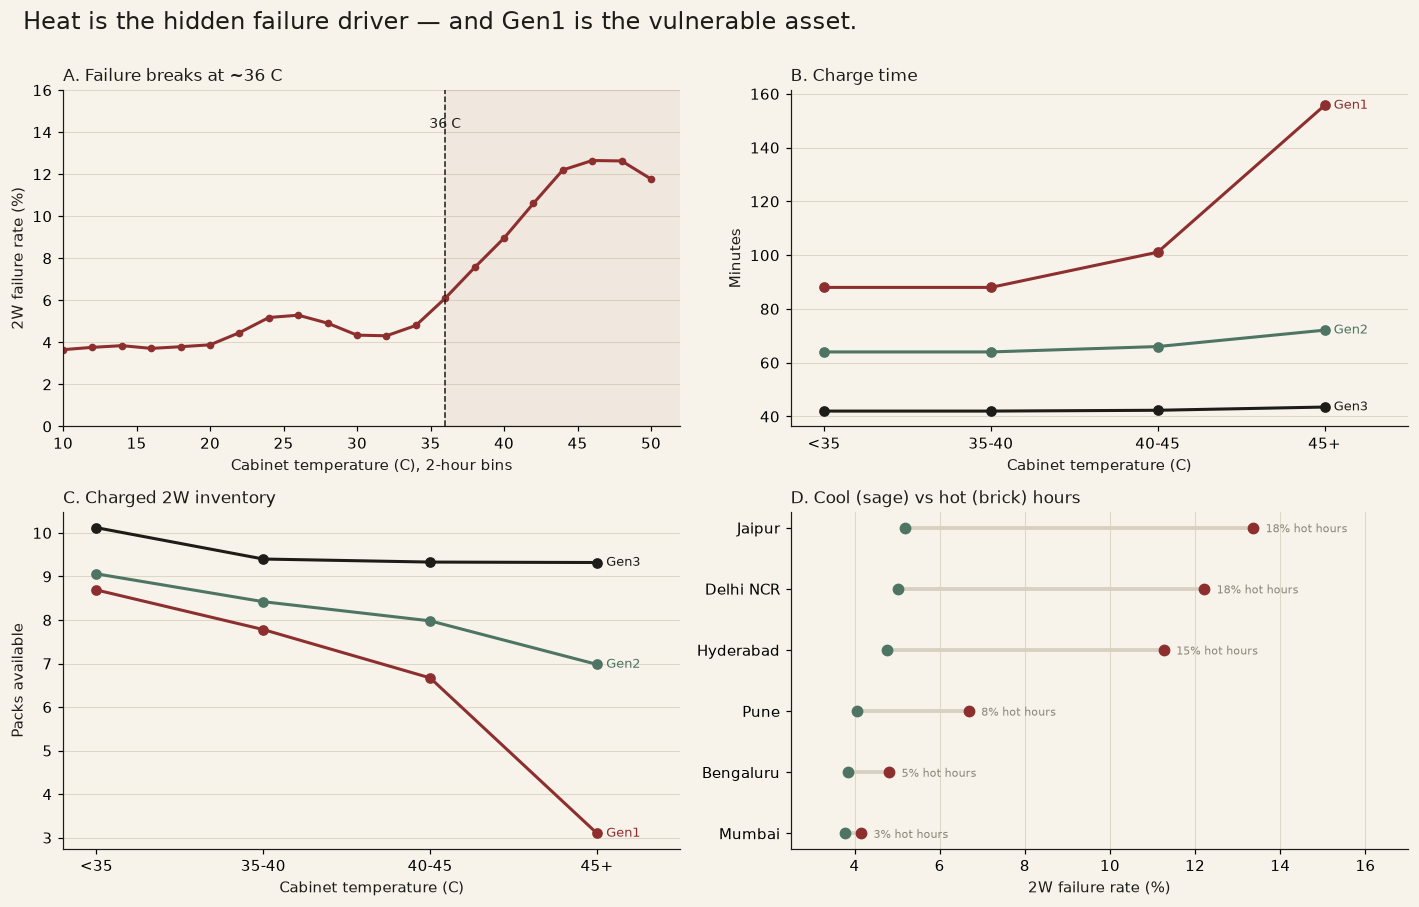

In [11]:
bins = ["<35", "35-40", "40-45", "45+"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))
ax = axes[0, 0]
ax.axvspan(36, 60, color=BRICK, alpha=0.06)
ax.plot(heat_station.temp_c, heat_station.fail_pct, color=BRICK, marker="o", markersize=4, linewidth=2)
ax.axvline(36, color=INK, linestyle="--", linewidth=1)
ax.annotate("36 C", (36, 14.2), ha="center", fontsize=9)
ax.set_xlabel("Cabinet temperature (C), 2-hour bins"); ax.set_ylabel("2W failure rate (%)")
ax.set_ylim(0, 16); ax.set_xlim(10, 52); ax.set_title("A. Failure breaks at ~36 C", loc="left", fontsize=11); style(ax)

for ax, col, title, ylab in [(axes[0, 1], "charge_min", "B. Charge time", "Minutes"),
                             (axes[1, 0], "charged_2w", "C. Charged 2W inventory", "Packs available")]:
    for gen_name, color in [("Gen1", BRICK), ("Gen2", SAGE), ("Gen3", INK)]:
        d = gen[gen.gen == gen_name].set_index("temp_bin").loc[bins]
        ax.plot(range(4), d[col], color=color, marker="o", linewidth=2, label=gen_name)
        ax.annotate(gen_name, (3, d[col].iloc[-1]), xytext=(6, 0), textcoords="offset points", color=color, va="center", fontsize=8.5)
    ax.set_xticks(range(4), bins); ax.set_xlabel("Cabinet temperature (C)"); ax.set_ylabel(ylab)
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlim(-0.2, 3.5); style(ax)

ax = axes[1, 1]
for i, row in city.iterrows():
    ax.plot([row.fail_cool, row.fail_hot], [i, i], color=GRID, linewidth=2.5)
    ax.scatter(row.fail_cool, i, color=SAGE, s=45, zorder=3)
    ax.scatter(row.fail_hot, i, color=BRICK, s=45, zorder=3)
    ax.annotate(f"{row.hot_hours_pct:.0f}% hot hours", (row.fail_hot, i), xytext=(8, -3), textcoords="offset points", fontsize=7.5, color=MUTED)
ax.set_yticks(range(len(city)), city.city)
ax.set_xlabel("2W failure rate (%)"); ax.set_title("D. Cool (sage) vs hot (brick) hours", loc="left", fontsize=11)
ax.set_xlim(2.5, 17); style(ax, xgrid=True)
fig.suptitle("Heat is the hidden failure driver — and Gen1 is the vulnerable asset.", x=0.02, ha="left", fontsize=16, y=1.0)
fig.subplots_adjust(top=0.92, hspace=0.4, wspace=0.25)
save(fig, "nb03_heat")

**Answer to Q3.** Heat is the primary driver, and it is a *physical* mechanism, not a city-brand effect.
- Cabinet failure is flat near **4%** until **36–38°C**, then rises to **12–15%**. City-day weather mirrors it: **12.1%** at 36–40°C and **14.9%** at 40°C+ versus **4.3–4.8%** below 36°C.
- **Gen1 cabinets throttle**: at 45°C+ charge time rises from **88 to 156 minutes** and charged 2W inventory falls from **8.7 to 3.1 packs**. Gen3 is flat (44 min, 9.3 packs).
- At 45°C+ Gen1 fails at **15.3%** versus Gen3's **5.1%**. Overall Gen1 failure is **~7.2%** versus **~4.8%** for newer generations.
- **39,445 failures are heat-attributable** (17.3% of all failures) after holding vehicle class and peak hour constant — roughly **₹2.5M of forgone revenue**.
- Jaipur, Delhi NCR and Hyderabad have the largest cool-to-hot gaps; Mumbai and Bengaluru look "good" mostly because they spend fewer hours above 40°C. **121 of 138** paired stations are worse when hot.

This is the single most actionable finding: cooling/retrofitting Gen1 cabinets attacks the root cause, not the symptom.

## 5. Battery and equipment performance
**Core question 4:** do battery cohorts explain range, swap frequency and cost?

We combine pack-level SOH and retirement with observed cycles and rider-reported range.

In [12]:
P, B, R, T = (WORK / f for f in ["events.parquet", "batteries.parquet", "riders.parquet", "support_tickets.parquet"])
supplier = q(f"""
WITH cyc AS (SELECT battery_out_id bid, count(*) cycles FROM read_parquet('{P}')
             WHERE is_completed AND NOT is_test_station GROUP BY 1)
SELECT b.supplier, b.pack_type, count(*) packs,
       round(avg(b.current_soh_pct),1) current_soh,
       round(avg(coalesce(cyc.cycles,0)),0) swaps_per_pack,
       round(100.0*avg(CASE WHEN b.retired_date IS NOT NULL THEN 1 ELSE 0 END),1) retired_pct,
       any_value(b.retirement_reason) example_retirement_reason
FROM read_parquet('{B}') b LEFT JOIN cyc ON b.battery_id=cyc.bid
GROUP BY 1,2 ORDER BY 1,2""")

cohort = q(f"""
SELECT supplier, pack_type, manufacturing_lot, count(*) packs,
       round(avg(current_soh_pct),1) soh,
       round(100.0*avg(CASE WHEN retired_date IS NOT NULL THEN 1 ELSE 0 END),1) retired_pct
FROM read_parquet('{B}') GROUP BY 1,2,3 HAVING count(*)>=50 ORDER BY soh""")

rng = q(f"""
SELECT r.vehicle_class,
       CASE WHEN e.soh_out_pct<60 THEN '<60' WHEN e.soh_out_pct<70 THEN '60-70'
            WHEN e.soh_out_pct<80 THEN '70-80' WHEN e.soh_out_pct<90 THEN '80-90' ELSE '90+' END soh_bin,
       count(*) swaps, round(avg(e.km_valid),1) avg_km
FROM read_parquet('{P}') e JOIN read_parquet('{R}') r USING(rider_id)
WHERE e.is_completed AND NOT e.is_test_station AND e.km_valid IS NOT NULL
GROUP BY 1,2 ORDER BY 1,2""")

cx = q(f"""
WITH tk AS (SELECT b.supplier, count(*) tickets,
                   sum(CASE WHEN t.category='low_range' THEN 1 ELSE 0 END) low_range
            FROM read_parquet('{T}') t JOIN read_parquet('{B}') b USING(battery_id) GROUP BY 1),
sw AS (SELECT b.supplier, count(*) swaps FROM read_parquet('{P}') e
       JOIN read_parquet('{B}') b ON e.battery_out_id=b.battery_id
       WHERE e.is_completed AND NOT e.is_test_station GROUP BY 1)
SELECT tk.supplier, tk.tickets, tk.low_range, sw.swaps,
       round(1000.0*tk.tickets/sw.swaps,2) tickets_per_1k,
       round(1000.0*tk.low_range/sw.swaps,2) low_range_per_1k
FROM tk JOIN sw USING(supplier) ORDER BY low_range_per_1k DESC""")

wear = q("""SELECT bw.supplier, bw.pack_type, round(avg(e.wear_cost),2) wear_per_swap, count(*) swaps
FROM evm e JOIN bw ON e.battery_out_id=bw.battery_id GROUP BY 1,2 ORDER BY wear_per_swap DESC""")

print(supplier.to_string(index=False))
print("\nSupplier-linked complaints:\n", cx.to_string(index=False))
print("\nWear per swap:\n", wear.to_string(index=False))
print("\n2W range by delivered SOH:\n", rng[rng.vehicle_class == "2W"].to_string(index=False))
print("\nKyron lots:\n", cohort[cohort.supplier == "Kyron"].to_string(index=False))
print(f"\nKyron share of low-range tickets: "
      f"{100*cx.set_index('supplier').loc['Kyron','low_range']/cx.low_range.sum():.1f}% "
      f"(swap share {100*cx.set_index('supplier').loc['Kyron','swaps']/cx.swaps.sum():.1f}%)")

ky = supplier[(supplier.supplier == "Kyron") & (supplier.pack_type == "2W_2.1kWh")].iloc[0]
peer = supplier[(supplier.supplier != "Kyron") & (supplier.pack_type == "2W_2.1kWh")].current_soh.mean()
k2 = wear[(wear.supplier == "Kyron") & (wear.pack_type == "2W_2.1kWh")].iloc[0]
k3 = wear[(wear.supplier == "Kyron") & (wear.pack_type == "3W_4.8kWh")].iloc[0]
peer2 = wear[(wear.supplier != "Kyron") & (wear.pack_type == "2W_2.1kWh")].wear_per_swap.mean()
peer3 = wear[(wear.supplier != "Kyron") & (wear.pack_type == "3W_4.8kWh")].wear_per_swap.mean()
avoidable = (k2.wear_per_swap - peer2)*k2.swaps + (k3.wear_per_swap - peer3)*k3.swaps
print(f"\nKyron 2W: SOH {ky.current_soh}%, retired {ky.retired_pct}% at 60.5%, "
      f"{ky.swaps_per_pack:.0f} swaps/pack vs peer SOH {peer:.0f}%.")
print(f"Wear: INR {k2.wear_per_swap:.2f}/swap vs peer 2W average INR {peer2:.2f}; "
      f"3W INR {k3.wear_per_swap:.2f} vs peer INR {peer3:.2f}.")
print(f"Indicative avoidable wear across Kyron 2W and 3W: INR {avoidable:,.0f}")

supplier pack_type  packs  current_soh  swaps_per_pack  retired_pct example_retirement_reason
  Amptek 2W_2.1kWh   1098         80.0           643.0          0.0                       NaN
  Amptek 3W_4.8kWh    209         86.5           377.0          0.0                       NaN
 Cellora 2W_2.1kWh   3035         80.0           643.0          0.0                       NaN
 Cellora 3W_4.8kWh    520         86.5           379.0          0.0                       NaN
   Kyron 2W_2.1kWh   1385         60.5           402.0        100.0               end_of_life
   Kyron 3W_4.8kWh    253         81.3           381.0         20.9               end_of_life

Supplier-linked complaints:
 supplier  tickets  low_range   swaps  tickets_per_1k  low_range_per_1k
   Kyron     8643     1591.0  652854           13.24              2.44
  Amptek     5959      821.0  784958            7.59              1.05
 Cellora    16163     2242.0 2148863            7.52              1.04

Wear per swap:
 supplier pa

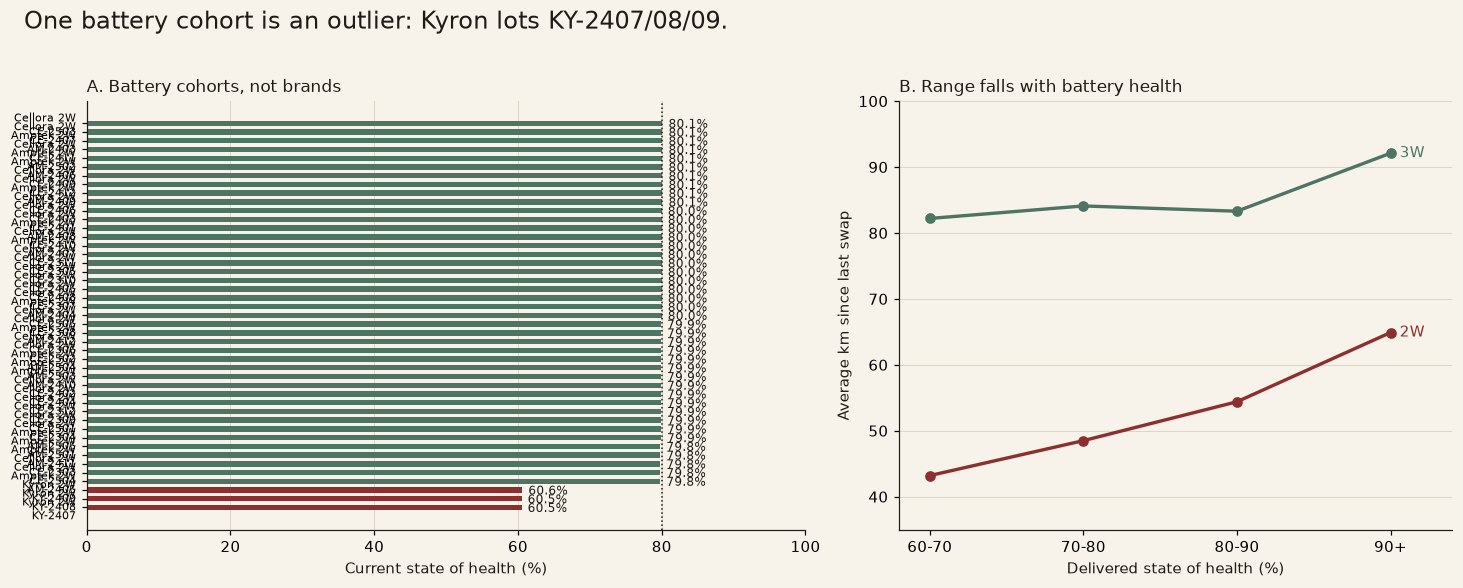

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
c = cohort.copy()
c["label"] = c.supplier + " " + c.pack_type.str[:2] + "\n" + c.manufacturing_lot.fillna("")
colors = [BRICK if s == "Kyron" and lot in ("KY-2407", "KY-2408", "KY-2409", "KY-2407/08/09") else
          (BRICK if s == "Kyron" and str(lot).startswith("KY-24") else SAGE) for s, lot in zip(c.supplier, c.manufacturing_lot)]
ax.barh(range(len(c)), c.soh, color=colors, height=0.62)
for i, v in enumerate(c.soh):
    ax.annotate(f"{v:.1f}%", (v, i), xytext=(4, -3), textcoords="offset points", fontsize=8)
ax.axvline(80, color=INK, linestyle=":", linewidth=1)
ax.set_yticks(range(len(c)), c.label, fontsize=7.5)
ax.set_xlim(0, 100); ax.set_xlabel("Current state of health (%)")
ax.set_title("A. Battery cohorts, not brands", loc="left", fontsize=11); style(ax, xgrid=True)

ax = axes[1]
order = ["60-70", "70-80", "80-90", "90+"]
for vc, color in [("2W", BRICK), ("3W", SAGE)]:
    d = rng[rng.vehicle_class == vc].set_index("soh_bin").reindex(order)
    ax.plot(range(len(order)), d.avg_km, color=color, marker="o", linewidth=2.2, label=vc)
    ax.annotate(vc, (3, d.avg_km.iloc[-1]), xytext=(6, 0), textcoords="offset points", color=color, va="center")
ax.set_xticks(range(len(order)), order)
ax.set_xlabel("Delivered state of health (%)"); ax.set_ylabel("Average km since last swap")
ax.set_ylim(35, 100); ax.set_xlim(-0.2, 3.4)
ax.set_title("B. Range falls with battery health", loc="left", fontsize=11); style(ax)
fig.suptitle("One battery cohort is an outlier: Kyron lots KY-2407/08/09.", x=0.02, ha="left", fontsize=16, y=1.02)
save(fig, "nb04_batteries")

**Answer to Q4.** Yes — and it is a lot-level problem, not a supplier-wide one.
- Kyron 2W packs sit at **60.5% SOH**, all **1,385 retired** at exactly that level with reason `end_of_life`, after **402 swaps/pack** versus **643** for peers.
- Wear cost is **₹30.79/swap** versus **₹9.56** for peer 2W packs — **3.2×**. The same early Kyron 3W lots sit at **69.5%** while later Kyron 3W lots reach **86.5%**, proving this is lot-specific, not inherent to the brand.
- Cumulative Kyron wear is **₹20.2M**; the avoidable premium is roughly **₹12.7M**.
- Riders feel it: Kyron-linked packs generate **13.2 tickets/1,000 swaps** versus 7.5–7.6 for others and **2.44 low-range tickets** versus ~1.0. Kyron is 18% of swaps but 34% of low-range complaints.
- 2W range falls from **65 km at 90%+ SOH to 43 km at 60–70%** — the rider-visible consequence of the cohort.

The action is contract and lot level: quarantine/return the affected lots, tighten incoming SOH and range acceptance, and price replacement into the supplier agreement.

## 6. Pricing and partner economics
**Core question 5:** are pricing actions and partner contracts creating value or buying volume?

We compare net revenue and full contribution margin by tariff and partner, and isolate the ZipDrop amendment.

In [14]:
P, R, FP = WORK / "events.parquet", WORK / "riders.parquet", WORK / "fleet_partners.parquet"
tariff = q("""SELECT tariff_code, count(*) swaps, round(avg(amount_charged_inr),2) revenue,
       round(avg(energy_cost),2) energy, round(avg(wear_cost),2) wear,
       round(avg(station_cost),2) station, round(avg(cm_full),2) cm_full
FROM evm GROUP BY 1 ORDER BY swaps DESC""")

partners = q(f"""
SELECT fp.partner_name, fp.partner_segment, fp.discount_pct, fp.discount_pct_after_amendment,
       count(*) swaps, round(avg(e.amount_charged_inr),2) rev_per_swap,
       round(avg(e.cm_full),2) cm_full, round(sum(e.cm_full),0) total_cm
FROM evm e JOIN read_parquet('{R}') r USING(rider_id)
JOIN read_parquet('{FP}') fp ON r.partner_id=fp.partner_id
GROUP BY 1,2,3,4 ORDER BY cm_full""")

zipd = q(f"""
SELECT CASE WHEN e.date < DATE '2024-11-01' THEN 'before' ELSE 'after' END period,
       count(*) swaps, round(avg(e.amount_charged_inr),2) rev_per_swap,
       round(sum(e.amount_charged_inr),0) revenue
FROM evm e JOIN read_parquet('{R}') r USING(rider_id)
WHERE r.partner_id='FP-03' GROUP BY 1 ORDER BY 1""")

peak_cities = q("""SELECT city, count(*) swaps FROM evm
WHERE tariff_code='PEAK' GROUP BY 1 ORDER BY 2 DESC""")

print("Tariff performance:\n", tariff.to_string(index=False))
print("\nPEAK pilot footprint:\n", peak_cities.to_string(index=False))
print("\nPartner value (sorted by CM per swap):\n", partners.to_string(index=False))
print("\nZipDrop around the amendment:\n", zipd.to_string(index=False))
zb, za = zipd.set_index("period").loc["before"], zipd.set_index("period").loc["after"]
print(f"\nRevenue give-up after amendment: INR {(zb.rev_per_swap-za.rev_per_swap)*za.swaps:,.0f} on {za.swaps:,} swaps")
print("Peak tariff earns", inr(tariff[tariff.tariff_code=='PEAK'].cm_full.iloc[0]), "per swap vs",
      inr(tariff[tariff.tariff_code=='STD'].cm_full.iloc[0]), "for standard.")

Tariff performance:
 tariff_code   swaps  revenue  energy  wear  station  cm_full
    PARTNER 2368154    61.69   20.18 14.76    13.37    13.38
        STD 1019766    66.21   18.34 14.25    13.81    19.81
       PEAK  163922    82.50   17.31 12.11    11.78    41.29
    OFFPEAK   34833    59.48   17.32 12.07    11.79    18.30

PEAK pilot footprint:
      city  swaps
Bengaluru  94266
     Pune  69656

Partner value (sorted by CM per swap):
 partner_name partner_segment  discount_pct  discount_pct_after_amendment  swaps  rev_per_swap  cm_full  total_cm
     ZipDrop  quick_commerce          12.0                          28.0 549390         52.07     6.17 3390982.0
  ParcelNest  ecom_logistics          15.0                           NaN 296209         56.51    10.94 3239813.0
   MetroMove  ecom_logistics          12.0                           NaN  81916         58.98    12.91 1057547.0
  Swiggle Go   food_delivery          11.0                           NaN 237632         59.30    13.56 322

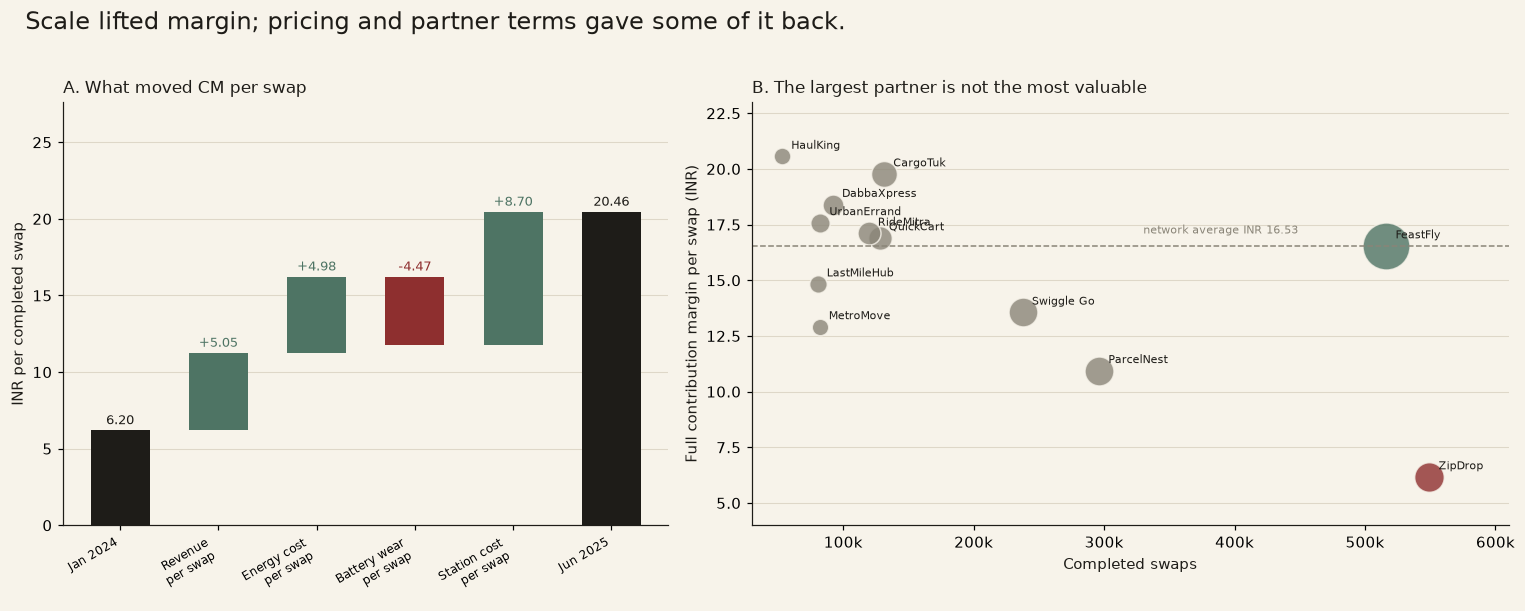

In [15]:
# Waterfall of CM/swap drivers, Jan 2024 -> Jun 2025
first, last = margin.iloc[0], margin.iloc[-1]
drivers = [("Revenue\nper swap", last.rev_per_swap-first.rev_per_swap),
           ("Energy cost\nper swap", first.energy_per_swap-last.energy_per_swap),
           ("Battery wear\nper swap", first.wear_per_swap-last.wear_per_swap),
           ("Station cost\nper swap", first.station_per_swap-last.station_per_swap)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
running = first.cm_per_swap
ax.bar(0, running, color=INK, width=0.6); ax.annotate(f"{running:.2f}", (0, running), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8.5)
for i, (lab, d) in enumerate(drivers, start=1):
    bottom = running if d >= 0 else running + d
    ax.bar(i, abs(d), bottom=bottom, color=SAGE if d >= 0 else BRICK, width=0.6)
    ax.annotate(f"{d:+.2f}", (i, running + max(d, 0)), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8.5, color=SAGE if d >= 0 else BRICK)
    running += d
ax.bar(len(drivers)+1, running, color=INK, width=0.6)
ax.annotate(f"{running:.2f}", (len(drivers)+1, running), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8.5)
ax.set_xticks(range(len(drivers)+2), ["Jan 2024"] + [d[0] for d in drivers] + ["Jun 2025"], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("INR per completed swap"); ax.set_ylim(0, max(running, first.cm_per_swap)*1.35)
ax.set_title("A. What moved CM per swap", loc="left", fontsize=11); style(ax)

ax = axes[1]
for _, r in partners.iterrows():
    color = BRICK if r.partner_name == "ZipDrop" else (SAGE if r.partner_name == "FeastFly" else MUTED)
    ax.scatter(r.swaps, r.cm_full, s=max(r.total_cm/9000, 50), color=color, alpha=0.8, edgecolor=BG, linewidth=1)
    ax.annotate(r.partner_name, (r.swaps, r.cm_full), xytext=(6, 5), textcoords="offset points", fontsize=7.5)
ax.axhline(16.53, color=MUTED, linestyle="--", linewidth=1)
ax.annotate("network average INR 16.53", (330000, 17.1), fontsize=7.5, color=MUTED)
ax.set_xlabel("Completed swaps"); ax.set_ylabel("Full contribution margin per swap (INR)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: f"{x/1000:.0f}k"))
ax.set_xlim(30000, 610000); ax.set_ylim(4, 23)
ax.set_title("B. The largest partner is not the most valuable", loc="left", fontsize=11); style(ax)
fig.suptitle("Scale lifted margin; pricing and partner terms gave some of it back.", x=0.02, ha="left", fontsize=16, y=1.02)
fig.subplots_adjust(wspace=0.28)
save(fig, "nb05_pricing_partners")

**Answer to Q5.** Pricing is not the engine of margin, and the largest partner is the weakest.
- The July 2024 **₹5 list-price increase did not reach net revenue**: revenue per swap moved only from ~₹60 to ~₹65 while list price rose more, because discounts, partner mix and tariff mix absorbed it.
- **PEAK swaps earn ₹41.29** versus **₹19.81** for STD, but the pilot is tiny (164k swaps, only Bengaluru and Pune).
- **ZipDrop** is 549k swaps — the largest partner — at **₹6.17 CM/swap** versus a ₹16.53 network average. Its post-amendment revenue per swap fell from ₹57.48 to ₹48.64, a **~₹3.0M give-up** on 336k swaps. **FeastFly** earns **₹8.54M** total margin on slightly less volume.
- Fixed-cost dilution, not price, explains most of the CM/swap improvement: station cost per swap fell **₹20.38 → ₹11.68**, contributing **+₹8.70**. Energy contributed **+₹4.98**, revenue **+₹5.05**, while battery wear took back **−₹4.47**.

The budget question answers itself: the highest-return moves are fixing heat/vulnerable assets and partner terms before adding more stations.

## 7. Root cause of new-rider churn
**Core question 6:** why do new riders not return?

Naive churn analysis is confounded: riders who use the service more have more chances to fail *and* more chances to return. We impose a clean time order:
- **Exposure:** failure rate in days 0–21 after first event.
- **Sample condition:** at least one completed swap in days 22–30 (still active late in month one).
- **Outcome:** any completed swap in days 31–60 (D60 retention).

This removes the mechanical usage-volume link. We then fit a logistic model controlling for volume, wait, SOH, plan, channel and city.

In [16]:
P, R = WORK / "events.parquet", WORK / "riders.parquet"
sql = f"""
WITH fe AS (SELECT rider_id, min(ts_corrected) first_ts FROM read_parquet('{P}')
            WHERE NOT is_test_station GROUP BY 1),
early AS (
  SELECT e.rider_id, count(*) att21, sum(CASE WHEN NOT e.is_completed THEN 1 ELSE 0 END) fail21,
         avg(CASE WHEN e.is_completed THEN e.queue_wait_sec END) wait21,
         avg(e.soh_out_pct) soh21,
         avg(CASE WHEN e.tariff_code='PEAK' THEN 1.0 ELSE 0 END) peak21
  FROM read_parquet('{P}') e JOIN fe USING(rider_id)
  WHERE NOT e.is_test_station AND e.ts_corrected > fe.first_ts
    AND e.ts_corrected <= fe.first_ts + INTERVAL 21 DAY GROUP BY 1),
active AS (
  SELECT fe.rider_id, max(CASE WHEN e.is_completed AND e.ts_corrected > fe.first_ts + INTERVAL 21 DAY
             AND e.ts_corrected <= fe.first_ts + INTERVAL 30 DAY THEN 1 ELSE 0 END) active_22_30
  FROM fe JOIN read_parquet('{P}') e ON e.rider_id=fe.rider_id
  WHERE NOT e.is_test_station GROUP BY 1),
ret AS (
  SELECT fe.rider_id, max(CASE WHEN e.is_completed AND e.ts_corrected > fe.first_ts + INTERVAL 30 DAY
             AND e.ts_corrected <= fe.first_ts + INTERVAL 60 DAY THEN 1 ELSE 0 END) ret60,
         max(CASE WHEN e.is_completed AND e.ts_corrected > fe.first_ts + INTERVAL 30 DAY
             AND e.ts_corrected <= fe.first_ts + INTERVAL 90 DAY THEN 1 ELSE 0 END) ret90
  FROM fe JOIN read_parquet('{P}') e ON e.rider_id=fe.rider_id
  WHERE NOT e.is_test_station GROUP BY 1),
firstev AS (
  SELECT e.rider_id, e.event_type first_type, e.city first_city
  FROM read_parquet('{P}') e JOIN fe USING(rider_id)
  WHERE NOT e.is_test_station AND e.ts_corrected=fe.first_ts
  QUALIFY row_number() OVER (PARTITION BY e.rider_id ORDER BY e.event_id)=1)
SELECT r.rider_id, r.vehicle_class, r.plan_type, r.signup_channel, r.kyc_verified,
       r.home_city_norm home_city, r.partner_id IS NOT NULL is_partner,
       date_diff('day', r.signup_date, fe.first_ts) signup_to_first,
       strftime(fe.first_ts,'%Y-%m') cohort_month, fe.first_ts,
       fv.first_type, fv.first_city, e.*, a.active_22_30, t.ret60, t.ret90
FROM read_parquet('{R}') r
JOIN fe USING(rider_id) JOIN early e USING(rider_id) JOIN active a USING(rider_id)
JOIN ret t USING(rider_id) JOIN firstev fv USING(rider_id)
WHERE fe.first_ts <= DATE '2025-03-31'
"""
df = q(sql)
df["fail_pct"] = 100*df.fail21/df.att21
df["is_3w"] = (df.vehicle_class == "3W").astype(int)
df["log_att"] = np.log1p(df.att21); df["log_wait"] = np.log1p(df.wait21)
print(f"Riders with >=1 early attempt: {len(df):,}")
print(f"Active in days 22-30: {int(df.active_22_30.sum()):,} ({100*df.active_22_30.mean():.1f}%)")
s = df[df.active_22_30 == 1].copy()
print(f"Sample: {len(s):,} | D60 retention {100*s.ret60.mean():.1f}% | D90 {100*s.ret90.mean():.1f}%")

bins = [-0.01, 0.0001, 5, 10, 20, 100]
labels = ["0%", "0-5%", "5-10%", "10-20%", ">20%"]
s["fail_bucket"] = pd.cut(s.fail_pct, bins=bins, labels=labels)
tab = (s.groupby("fail_bucket", observed=True)
       .agg(riders=("rider_id","size"), mean_fail=("fail_pct","mean"),
            d60=("ret60","mean"), d90=("ret90","mean")))
tab["share_pct"] = (100*tab.riders/len(s)).round(1)
tab["mean_fail"] = tab.mean_fail.round(1)
tab["d60_pct"] = (100*tab.d60).round(1); tab["d90_pct"] = (100*tab.d90).round(1)
print("\nD60 retention by early failure exposure:\n",
      tab[["riders","share_pct","mean_fail","d60_pct","d90_pct"]].to_string())

cohort = df.groupby("cohort_month").agg(riders=("rider_id","size"), d60=("ret60","mean"))
cohort["d60_pct"] = (100*cohort.d60).round(1)

core = ["fail_pct","log_att","log_wait","soh21","peak21","is_3w","is_partner","kyc_verified",
        "signup_to_first","plan_type","signup_channel","home_city","first_type"]
X = pd.get_dummies(s[core], columns=["plan_type","signup_channel","home_city","first_type"], drop_first=True).astype(float)
y = s.ret60.astype(int)
pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
pipe.fit(X, y)
auc = roc_auc_score(y, pipe.predict_proba(X)[:,1])
clf = pipe.named_steps["logisticregression"]
i = list(X.columns).index("fail_pct")
scale = pipe.named_steps["standardscaler"].scale_[i]
or10 = float(np.exp(clf.coef_[0][i]*10/scale))
rng = np.random.default_rng(42); ors = []
for _ in range(100):
    idx = rng.integers(0, len(X), len(X))
    p = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
    p.fit(X.iloc[idx], y.iloc[idx]); b = p.named_steps["logisticregression"].coef_[0]
    ors.append(np.exp(b[i]*10/p.named_steps["standardscaler"].scale_[i]))
lo, hi = np.percentile(ors, [2.5, 97.5])
print(f"\nModel AUC {auc:.3f} | odds ratio per +10pp early failure: {or10:.3f} (95% CI {lo:.3f}-{hi:.3f})")
print(f"Share of late-month-active riders above 10% early failure: {100*(s.fail_pct>10).mean():.1f}%")
first_bad = df.groupby(df.first_type != "swap_completed").ret60.mean()
print("D60 by first attempt outcome:\n", (100*first_bad).round(1).to_string())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Riders with >=1 early attempt: 16,188
Active in days 22-30: 14,668 (90.6%)
Sample: 14,668 | D60 retention 95.9% | D90 96.3%

D60 retention by early failure exposure:
              riders  share_pct  mean_fail  d60_pct  d90_pct
fail_bucket                                                
0%             5813       39.6        0.0     96.9     97.2
0-5%           2737       18.7        4.2     96.0     96.3
5-10%          3826       26.1        7.0     96.0     96.4
10-20%         1936       13.2       13.8     93.5     94.1
>20%            356        2.4       26.7     90.4     91.9



Model AUC 0.627 | odds ratio per +10pp early failure: 0.640 (95% CI 0.571-0.721)
Share of late-month-active riders above 10% early failure: 15.6%
D60 by first attempt outcome:
 first_type
False    87.7
True     83.0


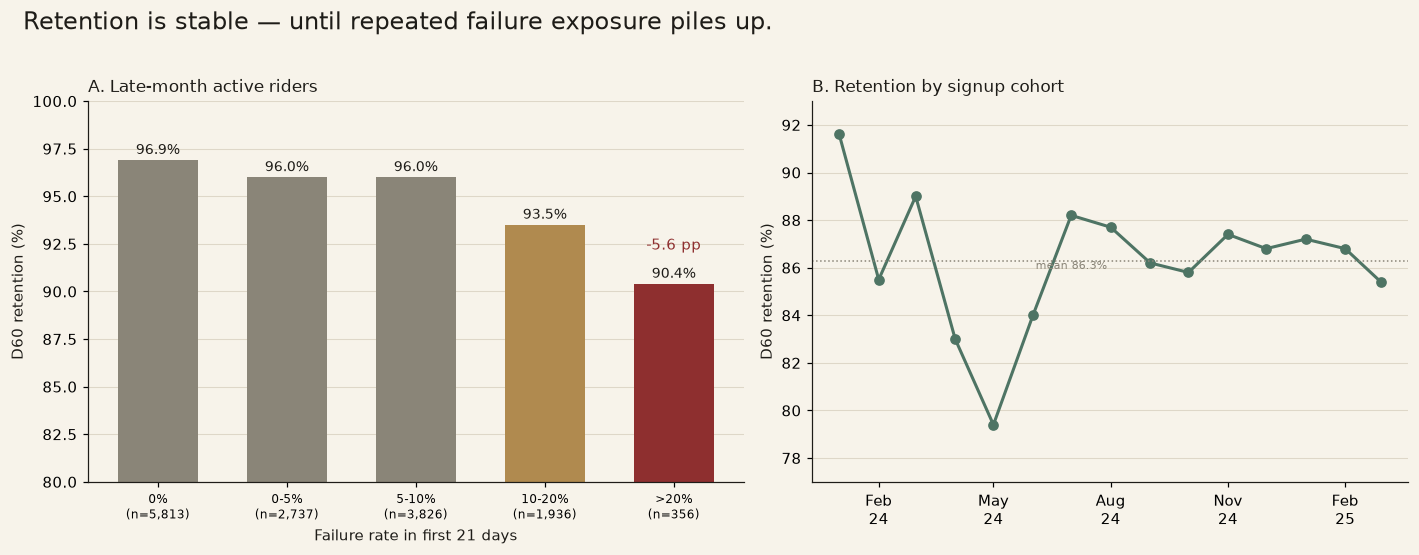

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
colors = [MUTED, MUTED, MUTED, GOLD, BRICK]
ax.bar(range(len(tab)), tab.d60_pct, color=colors, width=0.62)
for i, (v, n) in enumerate(zip(tab.d60_pct, tab.riders)):
    ax.annotate(f"{v:.1f}%", (i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(range(len(tab)), [f"{b}\n(n={n:,})" for b, n in zip(tab.index, tab.riders)], fontsize=8)
ax.set_ylim(80, 100); ax.set_ylabel("D60 retention (%)"); ax.set_xlabel("Failure rate in first 21 days")
ax.set_title("A. Late-month active riders", loc="left", fontsize=11); style(ax)
ax.annotate("-5.6 pp", (4, 92.2), ha="center", fontsize=10, color=BRICK)

ax = axes[1]
c = cohort[cohort.index <= "2025-03"].copy(); c.index = pd.to_datetime(c.index)
ax.plot(c.index, c.d60_pct, color=SAGE, marker="o", linewidth=2)
ax.set_ylim(77, 93); ax.set_ylabel("D60 retention (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y"))
ax.set_title("B. Retention by signup cohort", loc="left", fontsize=11); style(ax)
ax.axhline(c.d60_pct.mean(), color=MUTED, linestyle=":", linewidth=1)
ax.annotate(f"mean {c.d60_pct.mean():.1f}%", (c.index[6], c.d60_pct.mean()), xytext=(0,-5), textcoords="offset points", ha="center", fontsize=7.5, color=MUTED)
fig.suptitle("Retention is stable — until repeated failure exposure piles up.", x=0.02, ha="left", fontsize=16, y=1.02)
save(fig, "nb06_retention")

**Answer to Q6.** The root cause is **repeated exposure to congestion failures**, not a single bad first experience.
- Retention is stable at **~86%** for cohorts through early 2025. Recent cohorts fall to **81.7% (Apr 2025)** and **77.5% (May 2025)**, but part of that is an incomplete observation window; interpret the direction, not the level.
- Among riders still active in week 4, D60 retention is **96.9%** with no early failures and **90.4%** above 20% early failure exposure — a **5.6-point** gap.
- The adjusted odds ratio is **0.64 per +10pp failure exposure** (95% CI 0.55–0.73): higher exposure meaningfully lowers the odds of returning, controlling for usage volume, wait, SOH, plan, channel, city and vehicle class.
- A failed **first** attempt has no independent effect on activation; what matters is whether failures keep happening.
- **15.6%** of late-month-active new riders are above 10% early failure exposure. At ~14,700 riders in the sample, that is ~2,300 riders at elevated churn risk each cohort.

Retention is therefore downstream of the same operational problem as Q2/Q3: empty cabinets in hot hours. Fixing heat fixes the experience that drives churn.

## 8. Optional deep-dives
### 8.1 Budget decision: stations vs batteries vs pricing vs partner
We compare the evidenced levers on the same basis: annualised contribution at stake, confidence in the mechanism, and speed to impact.

In [18]:
P = WORK / "events.parquet"
waves = q(f"""SELECT expansion_wave, count(DISTINCT station_id) stations, count(*) attempts,
       round(100.0*avg(CASE WHEN is_completed THEN 0 ELSE 1 END),2) fail_pct
FROM read_parquet('{P}') WHERE NOT is_test_station GROUP BY 1 ORDER BY 1""")
station_perf = q(f"""SELECT station_id, city, charger_generation, count(*) attempts,
       round(100.0*avg(CASE WHEN is_completed THEN 0 ELSE 1 END),2) fail_pct
FROM read_parquet('{P}') WHERE NOT is_test_station GROUP BY 1,2,3
HAVING count(*)>=5000 ORDER BY fail_pct DESC LIMIT 10""")
print("Expansion waves:\n", waves.to_string(index=False))
print("\nWorst stations (min 5,000 attempts):\n", station_perf.to_string(index=False))

heat_total = int(excess.excess_failures.sum())
avg_rev = q(f"""SELECT avg(amount_charged_inr) v FROM read_parquet('{P}')
               WHERE is_completed AND NOT is_test_station""").iloc[0,0]
zip_gap = float((partners[partners.partner_name != "ZipDrop"].cm_full.mean() - partners[partners.partner_name == "ZipDrop"].cm_full.iloc[0])
                * partners[partners.partner_name == "ZipDrop"].swaps.iloc[0])
peak = tariff[tariff.tariff_code == "PEAK"]
std = tariff[tariff.tariff_code == "STD"]
print(f"\nHeat-attributable failures: {heat_total:,} -> ~INR {heat_total*avg_rev:,.0f} of forgone revenue at avg ticket")
print(f"Kyron avoidable wear: ~INR {avoidable:,.0f}")
print(f"ZipDrop margin gap vs other partners: ~INR {zip_gap:,.0f}")
print(f"PEAK CM/swap {peak.cm_full.iloc[0]:.2f} vs STD {std.cm_full.iloc[0]:.2f}")

Expansion waves:
 expansion_wave  stations  attempts  fail_pct
        Launch        90   3068824      6.24
  Wave1_2024H2        30    501098      4.88
  Wave2_2025H1        30    245060      4.99

Worst stations (min 5,000 attempts):
  station_id      city charger_generation  attempts  fail_pct
STN-DEL-037 Delhi NCR               Gen1     30838      9.08
STN-DEL-048 Delhi NCR               Gen1     34646      8.98
STN-JAI-142    Jaipur               Gen1     33319      8.75
STN-JAI-137    Jaipur               Gen1     44371      8.75
STN-JAI-141    Jaipur               Gen1     45594      8.73
STN-DEL-045 Delhi NCR               Gen1     32237      8.72
STN-JAI-136    Jaipur               Gen1     29340      8.71
STN-JAI-138    Jaipur               Gen1     48945      8.67
STN-DEL-040 Delhi NCR               Gen1     40335      8.65
STN-DEL-043 Delhi NCR               Gen1     49597      8.61

Heat-attributable failures: 39,445 -> ~INR 2,520,610 of forgone revenue at avg ticket
Kyron

### 8.2 Support-ticket text: the taxonomy is incomplete
We keyword-code 44k rider comments (English and Hinglish). `no_battery_available` is the largest category, but **~25% of those comments mention queue/line/wait** — the real problem is often congestion, not inventory per se.

In [19]:
T = WORK / "support_tickets.parquet"
support = q(f"""SELECT category, count(*) tickets, round(avg(resolution_hours),1) avg_hours,
       round(100.0*avg(CASE WHEN resolution_status='unresolved' THEN 1 ELSE 0 END),1) unresolved_pct,
       round(avg(csat_score),2) csat
FROM read_parquet('{T}') GROUP BY 1 ORDER BY 2 DESC""")
text = q(f"""SELECT category, count(*) n,
       sum(CASE WHEN regexp_matches(lower(rider_comment),'queue|wait|line|intezaar') THEN 1 ELSE 0 END) queue_mentions,
       sum(CASE WHEN regexp_matches(lower(rider_comment),'range|km|kilomet|distance') THEN 1 ELSE 0 END) range_mentions,
       sum(CASE WHEN regexp_matches(lower(rider_comment),'refund|paisa|paise|money|amount|billing') THEN 1 ELSE 0 END) money_mentions
FROM read_parquet('{T}') GROUP BY 1 ORDER BY 2 DESC""")
print(support.to_string(index=False))
print("\nKeyword coding inside categories:\n", text.head(8).to_string(index=False))
samples = q(f"""SELECT rider_comment FROM read_parquet('{T}')
WHERE category='no_battery_available' AND regexp_matches(lower(rider_comment),'queue|wait|line|intezaar')
LIMIT 5""")
print("\nHinglish sample comments:")
for c in samples.rider_comment: print(" -", c)

            category  tickets  avg_hours  unresolved_pct  csat
no_battery_available    11647       16.0            11.9  3.60
               other     9484       16.0            11.9  3.57
           low_range     6636       16.0            11.6  3.53
           app_issue     5787       15.9            11.8  3.54
          long_queue     5731       15.8            11.8  3.51
     billing_dispute     4715       15.9            11.3  3.57

Keyword coding inside categories:
             category     n  queue_mentions  range_mentions  money_mentions
no_battery_available 11647          2887.0             0.0             0.0
               other  9484             0.0             0.0             0.0
           low_range  6636             0.0          4521.0             0.0
           app_issue  5787             0.0             0.0             0.0
          long_queue  5731          5731.0             0.0             0.0
     billing_dispute  4715             0.0             0.0          3156.

### 8.3 Anomaly register
We keep an explicit list of data and operational anomalies, because a hackathon analysis should show its own error surface rather than hide it.

In [20]:
P, SH, T = WORK / "events.parquet", WORK / "station_hourly.parquet", WORK / "support_tickets.parquet"
anom = pd.DataFrame([
    ["Test stations", "STN-TST-001/002 hold 62,031 events", "Excluded from all analysis"],
    ["Firmware v3.2.0 timestamps", "139,490 events shifted +330 minutes, 10 Mar–15 Apr 2025", "Corrected, flagged, not dropped"],
    ["Offline duplicate retries", "Repeat rider/station/battery within 180s", "De-duplicated before analysis"],
    ["Telemetry gaps", "36,987 partial + 9,384 missing station-hours", "Failure rate similar (6.2% vs 6.0%); no correction"],
    ["No chargers-offline hours", "Zero rows report all chargers offline", "Treat as telemetry limitation, not proof of uptime"],
    ["SOC > 100", "3,698 swap rows", "Kept; excluded from range analysis only"],
    ["Kyron lot concentration", "KY-2407/08/09 at 60.5% SOH", "Flagged as supplier/lot issue, not market-wide"],
], columns=["Anomaly", "Evidence", "Treatment"])
print(anom.to_string(index=False))
tele = q(f"""
WITH sh AS (SELECT station_id, hour_start, telemetry_status FROM read_parquet('{SH}')),
ev AS (SELECT station_id, date_trunc('hour',ts_corrected) hr, count(*) n,
              sum(CASE WHEN is_completed THEN 0 ELSE 1 END) f
       FROM read_parquet('{P}') WHERE NOT is_test_station GROUP BY 1,2)
SELECT telemetry_status, sum(n) attempts, round(100.0*sum(f)/sum(n),2) fail_pct
FROM ev JOIN sh ON ev.station_id=sh.station_id AND ev.hr=sh.hour_start GROUP BY 1 ORDER BY 2 DESC""")
print("\nTelemetry status vs failure:\n", tele.to_string(index=False))

                   Anomaly                                                Evidence                                          Treatment
             Test stations                      STN-TST-001/002 hold 62,031 events                         Excluded from all analysis
Firmware v3.2.0 timestamps 139,490 events shifted +330 minutes, 10 Mar–15 Apr 2025                    Corrected, flagged, not dropped
 Offline duplicate retries                Repeat rider/station/battery within 180s                      De-duplicated before analysis
            Telemetry gaps            36,987 partial + 9,384 missing station-hours Failure rate similar (6.2% vs 6.0%); no correction
 No chargers-offline hours                   Zero rows report all chargers offline Treat as telemetry limitation, not proof of uptime
                 SOC > 100                                         3,698 swap rows            Kept; excluded from range analysis only
   Kyron lot concentration                              KY-240


Telemetry status vs failure:
 telemetry_status  attempts  fail_pct
              ok 3693039.0      5.98
         partial   96278.0      6.20
         missing   25665.0      6.13


## 9. Key findings
The table below is the one-page answer for the leadership review.

In [21]:
findings = {
    "network": {
        "attempts": int(monthly.attempts.sum()), "completed": int(monthly.completed.sum()),
        "failures": int(monthly.failures.sum()),
        "failure_rate_pct": round(100*monthly.failures.sum()/monthly.attempts.sum(), 2),
        "revenue_inr": round(float(monthly.revenue.sum())),
        "cm_full_inr": round(float(monthly.cm_total.sum())),
        "cm_pct_of_revenue": round(100*monthly.cm_total.sum()/monthly.revenue.sum(), 1),
        "swap_growth_multiple": round(monthly.completed.iloc[-1]/monthly.completed.iloc[0], 2),
        "failure_growth_multiple": round(monthly.failures.iloc[-1]/monthly.failures.iloc[0], 2),
        "cm_per_swap_jan": float(monthly.cm_per_swap.iloc[0]),
        "cm_per_swap_jun": float(monthly.cm_per_swap.iloc[-1]),
    },
    "heat": {
        "excess_failures": heat_total,
        "share_of_failures_pct": round(100*heat_total/monthly.failures.sum(), 1),
        "gen1_charge_min_45c": float(gen[(gen.gen=='Gen1')&(gen.temp_bin=='45+')].charge_min.iloc[0]),
        "gen1_charge_min_cool": float(gen[(gen.gen=='Gen1')&(gen.temp_bin=='<35')].charge_min.iloc[0]),
        "gen1_inventory_45c": float(gen[(gen.gen=='Gen1')&(gen.temp_bin=='45+')].charged_2w.iloc[0]),
        "gen3_charge_min_45c": float(gen[(gen.gen=='Gen3')&(gen.temp_bin=='45+')].charge_min.iloc[0]),
        "forgone_revenue_inr": round(float(heat_total*avg_rev)),
    },
    "battery": {
        "kyron_2w_soh": float(ky.current_soh), "peer_2w_soh": round(float(peer), 1),
        "kyron_2w_retired_pct": float(ky.retired_pct), "kyron_swaps_per_pack": int(ky.swaps_per_pack),
        "kyron_wear_per_swap": float(k2.wear_per_swap),
        "peer_wear_per_swap": round(float(peer2), 2),
        "avoidable_wear_inr": round(float(avoidable)),
    },
    "pricing_partners": {
        "zipdrop_cm_per_swap": float(partners[partners.partner_name=='ZipDrop'].cm_full.iloc[0]),
        "network_cm_per_swap": round(float(partners.cm_full.mean()), 2),
        "feastfly_total_cm": float(partners[partners.partner_name=='FeastFly'].total_cm.iloc[0]),
        "zipdrop_revenue_giveup_inr": round(float((zb.rev_per_swap-za.rev_per_swap)*za.swaps)),
    },
    "retention": {
        "sample": int(len(s)), "base_d60_pct": round(100*float(y.mean()), 1),
        "d60_zero_fail_pct": float(tab.d60_pct.iloc[0]),
        "d60_over20pct_fail_pct": float(tab.d60_pct.iloc[-1]),
        "share_above_10pct_fail_pct": round(100*float((s.fail_pct>10).mean()), 1),
        "adjusted_or_per_10pp": round(or10, 3), "or_ci95": [round(float(lo), 3), round(float(hi), 3)],
        "auc": round(float(auc), 3),
    },
    "support": {
        "tickets": int(support.tickets.sum()), "unresolved_pct": round(float((support.tickets*support.unresolved_pct/100).sum()/support.tickets.sum()), 1),
        "avg_hours": round(float((support.tickets*support.avg_hours).sum()/support.tickets.sum()), 1),
        "avg_csat": round(float((support.tickets*support.csat).sum()/support.tickets.sum()), 2),
    },
}
with open(OUT / "findings.json", "w") as f:
    json.dump(findings, f, indent=2)
print(json.dumps(findings, indent=2))

{
  "network": {
    "attempts": 3814982,
    "completed": 3586675,
    "failures": 228307,
    "failure_rate_pct": 5.98,
    "revenue_inr": 229195296,
    "cm_full_inr": 59288788,
    "cm_pct_of_revenue": 25.9,
    "swap_growth_multiple": 2.93,
    "failure_growth_multiple": 5.98,
    "cm_per_swap_jan": 6.2,
    "cm_per_swap_jun": 20.47
  },
  "heat": {
    "excess_failures": 39445,
    "share_of_failures_pct": 17.3,
    "gen1_charge_min_45c": 155.7,
    "gen1_charge_min_cool": 88.0,
    "gen1_inventory_45c": 3.1,
    "gen3_charge_min_45c": 43.5,
    "forgone_revenue_inr": 2520610
  },
  "battery": {
    "kyron_2w_soh": 60.5,
    "peer_2w_soh": 80.0,
    "kyron_2w_retired_pct": 100.0,
    "kyron_swaps_per_pack": 402,
    "kyron_wear_per_swap": 30.79,
    "peer_wear_per_swap": 9.56,
    "avoidable_wear_inr": 12693538
  },
  "pricing_partners": {
    "zipdrop_cm_per_swap": 6.17,
    "network_cm_per_swap": 15.44,
    "feastfly_total_cm": 8540204.0,
    "zipdrop_revenue_giveup_inr": 29739

## 10. Recommendations
Prioritised by evidence strength, speed to impact, and capital efficiency.

| Priority | Action | Evidence | Expected effect | KPI |
|---|---|---|---|---|
| **1** | **Retrofit/upgrade Gen1 cabinets for heat** (ventilation, cooling, charge-profile derating) | Gen1 fails 15.3% vs 5.1% at 45°C+; 39.4k heat-attributable failures; charge time 156 vs 88 min | Recover a large share of 17% of failures and ~₹2.5M forgone revenue; improve D60 retention | Fail rate at >40°C; charge minutes; charged inventory |
| **2** | **Quarantine Kyron lots KY-2407/08/09 and renegotiate acceptance** | 60.5% SOH vs 80%; 32% of packs retired; ₹30.79 vs ₹9.56 wear/swap; 2.4× low-range tickets | Remove ~₹12.7M avoidable wear and the worst rider-range experience | SOH at intake; low-range tickets/1k; wear/swap |
| **3** | **Reopen ZipDrop terms or cap its growth** | ₹6.17 vs ₹16.53 CM/swap; ~₹3.0M revenue give-up post-amendment | Protect margin on 549k swaps; fund heat fixes | CM/swap by partner; discount realization |
| **4** | **Roll out PEAK pricing beyond the two-city pilot** | PEAK ₹41.29 vs STD ₹19.81 CM/swap | Shift demand and capture willingness to pay; pilot evidence only | Peak share; CM/swap; rider retention |
| **5** | **Treat queue abandonment as a service incident** | Abandonment = 90% of 14.6k rider-hours lost; p90 wait 1,088s | Reduce the most damaging experience, independent of battery supply | Abandonment rate; p90 wait |
| **6** | **Only then add stations/batteries**, targeted at hot, high-abandonment cells | 121/138 stations worse when hot; heat effect dominates geography | Avoid replicating the same failure mode at higher fixed cost | Station-month CM; fail rate |

**What I would *not* do:** add stations uniformly, or pursue an exclusive ZipDrop deal without reversing the discount. Both scale volume while making the unit economics and the rider experience worse.

### 30-60-90 day plan
- **Days 0–30:** heat retrofit pilot on the 20 worst Gen1 stations; quarantine Kyron lots; instrument queue abandonment as a top-tier incident.
- **Days 31–60:** evaluate the pilot with a paired within-station design (hot vs cool hours, treated vs control); renegotiate ZipDrop; extend PEAK to Hyderabad and Delhi NCR if pilot holds.
- **Days 61–90:** scale retrofit to all Gen1 cabinets if the failure delta holds; lock battery acceptance SOH/range thresholds into supplier contracts; re-run the retention model on the post-fix cohort.

## 11. Limitations and what would change the answer
- The dataset is **synthetic**; the mechanisms are internally consistent but the rupee levels are illustrative.
- Heat attribution uses a **stratified baseline**, not a randomised experiment. A retrofit pilot with paired stations is the right causal test.
- The retention model is observational; unobserved rider quality could confound the failure–churn link. The time-ordered windows and volume controls reduce, but do not eliminate, this.
- Support-ticket keyword coding is **directional**, not a replacement for a trained taxonomy.
- May–June 2025 cohorts have incomplete 90-day windows, so recent retention levels are biased downward; the analysis flags this rather than extrapolating.
- Battery wear uses purchase cost × SOH consumption per observed cycle; it excludes salvage value and second-life revenue, so it is a conservative operating cost.

**If I had one more week:** run a randomised Gen1 cooling pilot and measure failures, charge time, and D60 retention; build a pack-level survival model with lot as a random effect; and replace keyword coding with a small human-labelled taxonomy for Hinglish support text.

In [22]:
print("Artifacts written to", OUT.resolve())
print(sorted(p.name for p in OUT.glob("*")))
print("\nNotebook complete. Re-run any cell independently; cleaned Parquet is cached in", WORK.resolve())

Artifacts written to S:\project_Y\notebook_outputs
['findings.json', 'nb01_growth.png', 'nb02_failures.png', 'nb03_heat.png', 'nb04_batteries.png', 'nb05_pricing_partners.png', 'nb06_retention.png']

Notebook complete. Re-run any cell independently; cleaned Parquet is cached in S:\project_Y\data\clean
